# RL-Guided Physics-Informed Transformer for Solving the 1D Advection Equation

## 1. Project Overview

This project explores the application of **Reinforcement Learning (RL) to improve the training of Physics-Informed Neural Networks (PINNs)** through adaptive collocation-point sampling. The proposed approach combines a Transformer-based encoder–decoder architecture with physics-informed learning and a tabular Q-Learning agent.

The objective is to solve the one-dimensional linear advection equation using a neural network that learns the underlying physical behaviour directly from the governing differential equation, rather than relying entirely on labelled training data.

The Transformer receives the initial condition and spatial information through its encoder, while the decoder processes the space-time coordinates at which the solution is required. A physics-informed loss function guides the model towards satisfying the governing equation and its initial and boundary conditions.

Reinforcement Learning is introduced to make the training process more adaptive. Instead of selecting all training points randomly or uniformly, a Q-Learning agent learns a sampling strategy based on the physics-related errors observed during training.

## 2. Problem Statement

The project considers the **one-dimensional linear advection equation**:

$$
\frac{\partial u(x,t)}{\partial t}
+c\frac{\partial u(x,t)}{\partial x}=0
$$

where:

- $u(x,t)$ represents the quantity being transported.
- $x$ represents the spatial coordinate.
- $t$ represents time.
- $c$ is the constant advection velocity, taken as $c=1$.

The equation describes the transport of a quantity through space at a constant velocity without changing its shape.

The problem is defined over the spatial and temporal domain:

$$
x,t\in[0,1]
$$

with the initial condition:

$$
u(x,0)=\sin(2\pi x)
$$

and periodic boundary conditions:

$$
u(0,t)=u(1,t)
$$

For this particular problem, the analytical solution is known:

$$
u(x,t)=\sin\left(2\pi(x-ct)\right)
$$

This analytical solution provides a reference against which the predictions of the trained model can be evaluated.

## 3. Project Objectives

The main objectives of this project are:

1. **Develop a Transformer-based architecture:** Implement an encoder–decoder Transformer from scratch to approximate the solution of the advection equation.

2. **Incorporate physical laws into training:** Use automatic differentiation to calculate the required derivatives and construct a physics-informed loss function based on the governing PDE, initial condition and periodic boundary conditions.

3. **Apply Reinforcement Learning:** Develop a tabular Q-Learning agent that learns to select collocation points for adaptive sampling during model training.

4. **Evaluate adaptive sampling strategies:** Compare the performance of three approaches: uniform random sampling, Residual-Based Adaptive Refinement (RAR), and Q-Learning-based adaptive sampling.

5. **Analyse model performance:** Evaluate the predicted solution using the analytical solution, PDE residuals, error metrics and visualisations.

## 4. What This Notebook Implements

The notebook develops and evaluates the complete workflow in the following stages:

- **Mathematical formulation:** Define the advection equation, initial condition, periodic boundary conditions and analytical solution.
- **Data generation:** Generate initial-condition points, interior collocation points, boundary points, validation points and test points.
- **Transformer implementation:** Build the encoder and decoder components, including embeddings, positional encoding, multi-head attention, feed-forward networks, residual connections and layer normalisation.
- **Physics-informed learning:** Construct a loss function that penalises violations of the PDE, initial condition and periodic boundary conditions.
- **Model training:** Train the Transformer using the physics-informed objective and save the trained model.
- **Reinforcement Learning:** Implement a tabular Q-Learning agent that learns an adaptive collocation-point sampling strategy using changes in physics-related violations as feedback.
- **Comparative evaluation:** Compare uniform sampling, RAR and Q-Learning-based sampling under a controlled adaptation and fine-tuning budget.
- **Results and analysis:** Visualise the predicted solution, analytical solution, error distribution, training behaviour and sampling patterns. Evaluate the methods using quantitative performance metrics.

## 5. Expected Outcome

The project aims to investigate whether Reinforcement Learning can guide the selection of collocation points and improve the training of a Physics-Informed Transformer.

The performance of the proposed approach is assessed against established sampling strategies. The analytical solution is used only for evaluation, while the Q-Learning agent receives feedback from physics-based violations during training.

The final results determine how effectively each sampling strategy improves the accuracy and physical consistency of the learned solution. The project also examines the limitations of the approach and whether RL provides a measurable advantage over conventional sampling methods.

# 1. Setup: Libraries, Seeds, Device and Configuration

This cell prepares the environment required for the project.

- **Libraries:** Imports the required Python libraries for numerical computation, deep learning, data handling and visualisation.
- **Random seeds:** Sets a fixed seed (42) to make experiments more reproducible.
- **Device selection:** Automatically detects whether a GPU or CPU is available for training.
- **Configuration:** Stores the model parameters, learning rates and training settings in a single configuration dictionary (`CFG`).
- **Run modes:** Supports `QUICK_RUN` for testing the complete pipeline and `FULL_RUN` for the actual experiment.

### Output and Execution Configuration

The current experiment is running in **FULL_RUN mode** using a CUDA-enabled GPU.

The configuration confirms:
- Baseline training: 400 epochs.
- Initial collocation points: 1,024.
- Q-Learning: 60 episodes with 5 actions per episode.
- Comparison methods: Uniform Sampling, RAR and Q-Learning, with 3 repetitions each.

The expected training budget is printed before execution to make the experiment configuration clear.

In [ ]:
import os, math, time, copy, random, warnings
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

SEED = 42; set_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
GPU = device.type == "cuda"
print("Device:", device, "| torch", torch.__version__)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3, "font.size": 10})

C_ADV = 1.0                      # advection speed c
EPS = 1e-8                       # epsilon protection for every denominator in rewards / relative metrics

# ======================= RUN MODE: edit this line (or set env var RUN_MODE) =======================
RUN_MODE = "FULL_RUN"          # "QUICK_RUN" or "FULL_RUN"
assert RUN_MODE in ("QUICK_RUN", "FULL_RUN"), "RUN_MODE must be 'QUICK_RUN' or 'FULL_RUN'"
RUN_PROFILES = {
    # tiny budgets: runs EVERY stage of the pipeline in a short time (smoke test, not a scientific result)
    "QUICK_RUN": dict(N0=128, BATCH=64, EPOCHS=3, K=4, M=32, T=2, FT=2, EPISODES=3, N_REPEAT=1),
    # substantial experiment (budgets shrink automatically on CPU)
    "FULL_RUN":  dict(N0=1024, BATCH=256, EPOCHS=400 if GPU else 150, K=8, M=256,
                      T=5 if GPU else 4, FT=40 if GPU else 20, EPISODES=60 if GPU else 30, N_REPEAT=3),
}
CFG = dict(d_model=64, n_heads=4, n_enc=2, n_dec=2, d_ff=128,
           dropout=0.0,          # 0 for PINNs: random dropout noise would corrupt derivatives (see Part O)
           N_ENC=64,             # encoder sequence length (grid points carrying u(x,0))
           LR=1e-3, FT_LR=5e-4)
CFG.update(RUN_PROFILES[RUN_MODE])
# K: number of x-regions, M: points added per action, T: actions per episode, FT: fine-tune steps per action
LAM = dict(pde=1.0, ic=10.0, bc=1.0, d=0.1)    # loss weights (explained in Section 5)
DECODER_MODE = "independent"                   # decision taken in Part O2: each query = its own length-1 sequence

def print_expected_budget(c):
    spe = math.ceil(c["N0"] / c["BATCH"]); base_steps = c["EPOCHS"] * spe
    adapt_steps, added = c["T"] * c["FT"], c["T"] * c["M"]
    pol_steps, pol_trans = c["EPISODES"] * adapt_steps, c["EPISODES"] * c["T"]
    n_s, n_pairs = 3 * c["K"], 3 * c["K"] * c["K"]
    print("=" * 72); print(f"EXPECTED TRAINING CONFIGURATION  ->  RUN_MODE = {RUN_MODE}"); print("=" * 72)
    print(f"Baseline PINN      : {c['EPOCHS']} epochs x {spe} mini-batches (N0={c['N0']}, batch={c['BATCH']}) = {base_steps} optimizer steps")
    print(f"Each adaptation run: T={c['T']} actions x (add M={c['M']} pts + FT={c['FT']} fine-tune steps) = {added} new points, {adapt_steps} fine-tune steps")
    print(f"  identical budget for Uniform, RAR and Q-Learning; repeated N_REPEAT={c['N_REPEAT']}x each  ->  {3*c['N_REPEAT']*adapt_steps} fine-tune steps in total")
    print(f"RL policy learning : {c['EPISODES']} episodes x T={c['T']} = {pol_trans} transitions, {pol_steps} fine-tune steps (reported SEPARATELY)")
    print(f"Q-table            : {n_s} states x {c['K']} actions = {n_pairs} (s,a) pairs vs {pol_trans} transitions available to visit them")
    if RUN_MODE == "QUICK_RUN": print("QUICK_RUN = smoke test of the full pipeline. Do NOT draw scientific conclusions from its numbers.")
    print("=" * 72)
print(CFG); print_expected_budget(CFG)

Device: cuda | torch 2.14.1+cu130
{'d_model': 64, 'n_heads': 4, 'n_enc': 2, 'n_dec': 2, 'd_ff': 128, 'dropout': 0.0, 'N_ENC': 64, 'LR': 0.001, 'FT_LR': 0.0005, 'N0': 1024, 'BATCH': 256, 'EPOCHS': 400, 'K': 8, 'M': 256, 'T': 5, 'FT': 40, 'EPISODES': 60, 'N_REPEAT': 3}
EXPECTED TRAINING CONFIGURATION  ->  RUN_MODE = FULL_RUN
Baseline PINN      : 400 epochs x 4 mini-batches (N0=1024, batch=256) = 1600 optimizer steps
Each adaptation run: T=5 actions x (add M=256 pts + FT=40 fine-tune steps) = 1280 new points, 200 fine-tune steps
  identical budget for Uniform, RAR and Q-Learning; repeated N_REPEAT=3x each  ->  1800 fine-tune steps in total
RL policy learning : 60 episodes x T=5 = 300 transitions, 12000 fine-tune steps (reported SEPARATELY)
Q-table            : 24 states x 8 actions = 192 (s,a) pairs vs 300 transitions available to visit them


# 2. Mathematical Problem: 1D Linear Advection Equation

The project solves the **one-dimensional linear advection equation**, which describes how a quantity is transported through space at a constant velocity.

## Governing Equation

$$
\frac{\partial u}{\partial t}
+c\frac{\partial u}{\partial x}=0
$$

where $c=1$ is the advection velocity, and the spatial and temporal domains are:

$$
x,t\in[0,1]
$$

## Initial and Boundary Conditions

The initial condition defines the starting wave:

$$
u(x,0)=\sin(2\pi x)
$$

Periodic boundary conditions ensure that the wave leaving one end of the domain re-enters from the other:

$$
u(0,t)=u(1,t)
$$

## Analytical Solution

For this problem, the exact solution is known:

$$
u(x,t)=\sin\left(2\pi(x-ct)\right)
$$

This represents a sinusoidal wave travelling at constant velocity without changing its shape.

## Numerical Verification and Visualisation

The code performs three checks using automatic differentiation:

- Verifies that the analytical solution satisfies the governing PDE.
- Checks that the initial condition is satisfied.
- Checks that the periodic boundary condition holds.

It also plots the initial wave and its evolution at different time instants.

**Why is this important?**

The analytical solution provides a reference for evaluating the accuracy of the trained Transformer using metrics such as MSE, MAE and relative $L_2$ error. It is used for evaluation, not for calculating the physics-informed training loss or the Q-Learning reward.

max |u_t + c u_x| = 0.0
✔ analytical solution satisfies PDE, IC and periodic BC


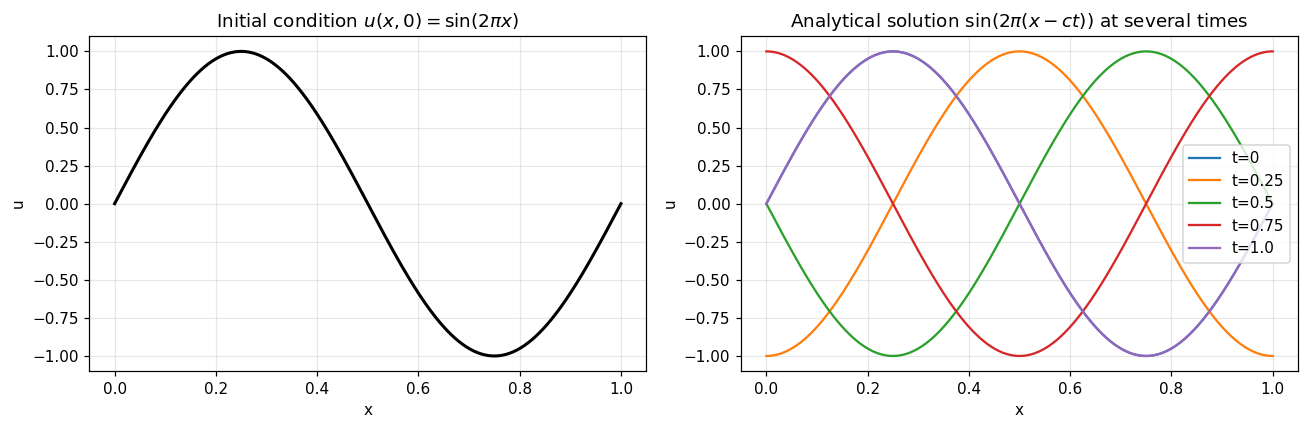

In [ ]:
def u0(x):        return torch.sin(2*math.pi*x)                 # initial condition
def u_exact(x,t): return torch.sin(2*math.pi*(x - C_ADV*t))      # analytical solution

# ---- check: analytical solution satisfies the PDE (derivatives via autograd) ----
xs = torch.rand(1000, requires_grad=True); ts = torch.rand(1000, requires_grad=True)
u = u_exact(xs, ts)
u_t, u_x = torch.autograd.grad(u, [ts, xs], grad_outputs=torch.ones_like(u))
print("max |u_t + c u_x| =", (u_t + C_ADV*u_x).abs().max().item())
assert (u_t + C_ADV*u_x).abs().max() < 1e-4
tt = torch.rand(100)
assert (u_exact(torch.zeros(100), tt) - u_exact(torch.ones(100), tt)).abs().max() < 1e-5   # periodic BC
assert (u_exact(xs.detach(), torch.zeros(1000)) - u0(xs.detach())).abs().max() < 1e-6      # IC
print("✔ analytical solution satisfies PDE, IC and periodic BC")

xx = torch.linspace(0, 1, 400)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(xx, u0(xx), "k", lw=2); ax[0].set_title("Initial condition $u(x,0)=\\sin(2\\pi x)$"); ax[0].set_xlabel("x"); ax[0].set_ylabel("u")
for tv in [0, .25, .5, .75, 1.0]:
    ax[1].plot(xx, u_exact(xx, torch.tensor(tv)), label=f"t={tv}")
ax[1].set_title("Analytical solution $\\sin(2\\pi(x-ct))$ at several times"); ax[1].set_xlabel("x"); ax[1].set_ylabel("u"); ax[1].legend()
plt.tight_layout(); plt.show()

# 3. Problem Formulation and Data Generation

## 3.1 Coordinate-Conditioned Transformer

The model uses a **coordinate-conditioned encoder–decoder architecture**. Since the initial condition is fixed, it is provided to the encoder as context, while the decoder receives the space-time coordinates at which the solution must be predicted.

The inputs and output have the following structure:

| Component | Description | Shape |
|---|---|---|
| Encoder input | Spatial coordinates and initial values, $[x_i,u(x_i,0)]$ | $(1,64,2)$ |
| Decoder input | Query coordinates, $(x,t)$ | $(B,1,2)$ |
| Model output | Predicted solution, $\hat{u}(x,t)$ | $(B,1,1)$ |

This allows the model to predict the solution at different spatial and temporal coordinates without requiring a predefined solution grid.

## 3.2 Data Point Sets

Different sets of points are generated for training, validation and testing:

- **Interior collocation points:** Random points inside the domain used to calculate the PDE residual and train the model.
- **Initial condition points:** Points at $t=0$ used to enforce the initial condition.
- **Boundary points:** Points at $x=0$ and $x=1$ used to enforce periodic boundary conditions.
- **Validation points:** Fixed random points used for model checkpoint selection and physics-based RL feedback.
- **Test points:** A fixed $101\times101$ grid used for final performance evaluation.

Training points update the model parameters, validation points help guide training decisions, and test points are reserved for final evaluation.

## 3.3 Input Normalisation

Both spatial and temporal coordinates already lie in the range $[0,1]$. Therefore, they are directly provided to the network without additional scaling.

## 3.4 Output and Visualisation

The code generates the encoder input, interior collocation pool, validation points and test grid. It also prints the encoder input shape and displays the distribution of the different point sets across the $(x,t)$ domain.

These visualisations help verify that the data has been generated correctly before model training begins.

Encoder input shape: (1, 64, 2)
          Set         Points
Interior pool           1024
  IC per step            256
  BC per step 128 (x2 sides)
   Validation           2000
    Test grid          10201


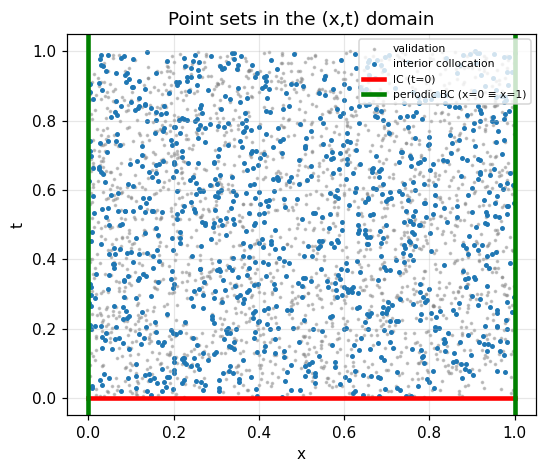

In [ ]:
N_ENC, N0 = CFG["N_ENC"], CFG["N0"]
gen = torch.Generator().manual_seed(SEED)
pool_x0 = torch.rand(N0, generator=gen).to(device); pool_t0 = torch.rand(N0, generator=gen).to(device)   # interior collocation pool
vg = torch.Generator().manual_seed(SEED + 100)
val_x = torch.rand(2000, generator=vg).to(device); val_t = torch.rand(2000, generator=vg).to(device)
NT = 101
Xg, Tg = torch.meshgrid(torch.linspace(0, 1, NT), torch.linspace(0, 1, NT), indexing="ij")
test_x, test_t = Xg.reshape(-1).to(device), Tg.reshape(-1).to(device)
test_u = u_exact(test_x, test_t)

x_enc = torch.arange(N_ENC).float() / N_ENC                       # periodic grid (x=1 excluded, equals x=0)
ENC_IN = torch.stack([x_enc, u0(x_enc)], -1).unsqueeze(0).to(device)   # (1,64,2)
print("Encoder input shape:", tuple(ENC_IN.shape))
assert ENC_IN.shape == (1, N_ENC, 2)

print(pd.DataFrame({"Set": ["Interior pool", "IC per step", "BC per step", "Validation", "Test grid"],
                    "Points": [N0, 256, "128 (x2 sides)", len(val_x), len(test_x)]}).to_string(index=False))

plt.figure(figsize=(5.5, 4.5))
plt.scatter(val_x.cpu(), val_t.cpu(), s=2, c="gray", alpha=.4, label="validation")
plt.scatter(pool_x0.cpu(), pool_t0.cpu(), s=5, c="C0", label="interior collocation")
plt.plot(np.linspace(0, 1, 50), 0*np.linspace(0, 1, 50), "r", lw=3, label="IC (t=0)")
plt.axvline(0, c="g", lw=3, label="periodic BC (x=0 ≡ x=1)"); plt.axvline(1, c="g", lw=3)
plt.xlabel("x"); plt.ylabel("t"); plt.title("Point sets in the (x,t) domain"); plt.legend(loc="upper right", fontsize=7); plt.show()

# fixed PHYSICS validation sets (no analytical solution needed): IC points and periodic-BC times, used by the RL reward
pg = torch.Generator().manual_seed(SEED + 300)
ic_val_x = torch.rand(512, generator=pg).to(device); bc_val_t = torch.rand(256, generator=pg).to(device)

# 4. The Encoder–Decoder Transformer, from scratch

Data flow (every box is implemented separately below):

`IC tokens → [Embed → +PosEnc → (MHSA → Add&Norm → FFN → Add&Norm)×2] → memory`
`query (x,t) → [Embed → +PosEnc → (Self-Attn → A&N → Cross-Attn(memory) → A&N → FFN → A&N)×2] → Linear → û`

Allowed building blocks: `nn.Linear, nn.LayerNorm, nn.Dropout`. **Not used:** `nn.Transformer*`, `nn.MultiheadAttention`.

---


### Part A — Input Embedding

The encoder receives two features for each input token: the spatial coordinate $x_i$ and its initial condition value $u(x_i,0)$.

An embedding layer transforms these two input features into a higher-dimensional vector of size 64 using a learnable linear transformation.

$$
E=XW_e+b_e
$$

This allows the Transformer to work with richer representations instead of the original two-dimensional inputs.

**Output:** The input shape changes from $(1,64,2)$ to $(1,64,64)$.

In [ ]:
class LinearEmbedding(nn.Module):
    """Maps raw token features (in_dim) -> d_model with one learnable linear layer."""
    def __init__(self, in_dim, d_model):
        super().__init__(); self.lin = nn.Linear(in_dim, d_model)
    def forward(self, x): return self.lin(x)

emb = LinearEmbedding(2, CFG["d_model"]).to(device)
E = emb(ENC_IN)
print("input", tuple(ENC_IN.shape), "-> embedded", tuple(E.shape))
assert E.shape == (1, N_ENC, CFG["d_model"])

input (1, 64, 2) -> embedded (1, 64, 64)


### Part B — Sinusoidal Positional Encoding

Self-attention does not automatically understand the order of input tokens. Positional encoding adds information about the position of each token to its embedding.

This implementation uses sinusoidal functions:

$$
PE(pos,2i)=\sin\left(\frac{pos}{10000^{2i/d}}\right)
$$

$$
PE(pos,2i+1)=\cos\left(\frac{pos}{10000^{2i/d}}\right)
$$

The positional encoding is added to the embeddings without changing their dimensions.

**Output:** The shape remains $(1,64,64)$. The code also visualises the sinusoidal positional encoding.

after PE: (1, 64, 64) | change from PE (mean abs): 0.5850645303726196


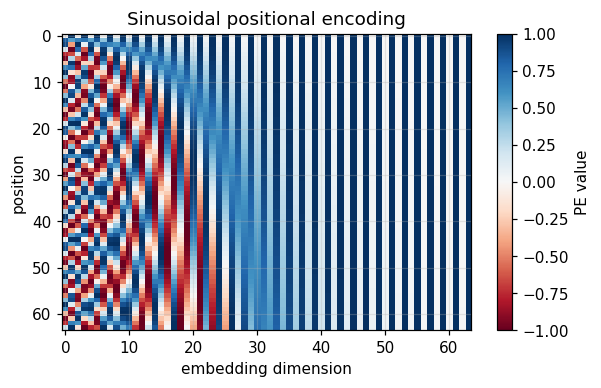

In [ ]:
class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=512):
        super().__init__()
        pe = torch.zeros(max_len, d_model)
        pos = torch.arange(max_len).float().unsqueeze(1)                          # (max_len,1)
        div = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(pos * div); pe[:, 1::2] = torch.cos(pos * div)
        self.register_buffer("pe", pe.unsqueeze(0))                               # (1,max_len,d)
    def forward(self, x): return x + self.pe[:, :x.size(1)]

pos_enc = PositionalEncoding(CFG["d_model"]).to(device)
Ep = pos_enc(E)
print("after PE:", tuple(Ep.shape), "| change from PE (mean abs):", (Ep - E).abs().mean().item())
plt.figure(figsize=(6, 3.5)); plt.imshow(pos_enc.pe[0, :N_ENC].cpu(), aspect="auto", cmap="RdBu")
plt.colorbar(label="PE value"); plt.xlabel("embedding dimension"); plt.ylabel("position"); plt.title("Sinusoidal positional encoding"); plt.show()

### Part C — Scaled Dot-Product Attention

Attention allows the model to identify which input tokens are more relevant to a particular query.

Each input is transformed into three vectors:

- **Query (Q):** What information am I looking for?
- **Key (K):** What information does each token contain?
- **Value (V):** What information should be passed forward?

The attention operation is:

$$
Attention(Q,K,V)=
softmax\left(\frac{QK^T}{\sqrt{d_k}}\right)V
$$

The scaling factor $\sqrt{d_k}$ prevents attention scores from becoming excessively large, helping maintain stable gradients.

Softmax converts the scores into attention weights, which are used to calculate a weighted combination of the values.

**Output:** The code verifies the attention weight dimensions and confirms that each row of attention weights sums to 1.

In [ ]:
def scaled_dot_product_attention(Q, K, V, mask=None):
    d_k = Q.size(-1)
    scores = Q @ K.transpose(-2, -1) / math.sqrt(d_k)          # (...,Lq,Lk)
    if mask is not None:
        scores = scores.masked_fill(~mask, float("-inf"))      # forbidden positions get weight 0 after softmax
    w = F.softmax(scores, dim=-1)                              # each row sums to 1
    return w @ V, w

q = torch.randn(1, 5, 8); k = torch.randn(1, 5, 8); v = torch.randn(1, 5, 8)
out, w = scaled_dot_product_attention(q, k, v)
print("Q,K,V", tuple(q.shape), "-> weights", tuple(w.shape), "-> output", tuple(out.shape))
print("attention weights (rows sum to 1):\n", w[0].detach().numpy().round(2))
assert torch.allclose(w.sum(-1), torch.ones(1, 5), atol=1e-5)
q64, k64 = torch.randn(10000, 64), torch.randn(10000, 64)
print("std of scores  unscaled: %.2f | scaled: %.2f  (why we divide by sqrt(d_k))" % ((q64*k64).sum(-1).std(), ((q64*k64).sum(-1)/8).std()))

Q,K,V (1, 5, 8) -> weights (1, 5, 5) -> output (1, 5, 8)
attention weights (rows sum to 1):
 [[0.35 0.2  0.02 0.15 0.28]
 [0.2  0.14 0.05 0.29 0.32]
 [0.21 0.13 0.11 0.38 0.17]
 [0.14 0.09 0.55 0.08 0.14]
 [0.14 0.2  0.11 0.19 0.35]]
std of scores  unscaled: 7.96 | scaled: 1.00  (why we divide by sqrt(d_k))


### Part D — Multi-Head Attention

Multi-Head Attention uses multiple attention mechanisms in parallel, allowing the model to learn different relationships between tokens.

In this project, the embedding dimension is 64 and the number of attention heads is 4.

$$
d_k=\frac{d_{model}}{h}=\frac{64}{4}=16
$$

Each head processes a separate 16-dimensional representation. Their outputs are concatenated and passed through a final linear projection.

The same implementation supports both self-attention and cross-attention.

**Output:** Four attention heads produce an output of shape $(1,64,64)$, with attention weights of shape $(1,4,64,64)$.

In [ ]:
class MultiHeadAttention(nn.Module):
    def __init__(self, d_model, n_heads):
        super().__init__()
        assert d_model % n_heads == 0
        self.h, self.dk = n_heads, d_model // n_heads
        self.Wq, self.Wk, self.Wv, self.Wo = [nn.Linear(d_model, d_model) for _ in range(4)]
    def split(self, x):                                                    # (B,L,d)->(B,h,L,dk)
        B, L, _ = x.shape; return x.view(B, L, self.h, self.dk).transpose(1, 2)
    def forward(self, q_in, kv_in, mask=None, return_attn=False):
        Q, K, V = self.split(self.Wq(q_in)), self.split(self.Wk(kv_in)), self.split(self.Wv(kv_in))
        out, w = scaled_dot_product_attention(Q, K, V, mask)               # (B,h,Lq,dk)
        B, _, L, _ = out.shape
        out = self.Wo(out.transpose(1, 2).contiguous().view(B, L, self.h * self.dk))   # concat heads + project
        return (out, w) if return_attn else out

mha = MultiHeadAttention(64, 4).to(device)
o, w = mha(Ep, Ep, return_attn=True)
print("self-attn in", tuple(Ep.shape), "-> out", tuple(o.shape), "| weights (B,h,L,L):", tuple(w.shape))
assert o.shape == Ep.shape

self-attn in (1, 64, 64) -> out (1, 64, 64) | weights (B,h,L,L): (1, 4, 64, 64)


### Part E — Add & Norm

Add & Norm combines a sub-layer's output with its original input using a residual connection, followed by Layer Normalisation.

$$
Output=LayerNorm(x+Sublayer(x))
$$

The residual connection helps preserve information and supports better gradient flow, while Layer Normalisation keeps the feature values stable during training.

**Output:** The input and output shapes remain unchanged, $(1,64,64)$.

In [ ]:
class AddNorm(nn.Module):
    def __init__(self, d_model, dropout=0.0):
        super().__init__(); self.norm = nn.LayerNorm(d_model); self.drop = nn.Dropout(dropout)
    def forward(self, x, sub_out): return self.norm(x + self.drop(sub_out))

an = AddNorm(64).to(device); y = an(Ep, o)
print("shape", tuple(y.shape), "| per-token mean≈%.1e, std≈%.3f" % (y.mean(-1).abs().max().item(), y.std(-1).mean().item()))

shape (1, 64, 64) | per-token mean≈6.0e-08, std≈1.008


### Part F — Position-wise Feed-Forward Network (FFN)

The Feed-Forward Network applies additional transformations to each token independently. Unlike attention, it does not mix information between different tokens.

It consists of two linear layers with GELU activation in between:

$$
FFN(x)=W_2\,GELU(W_1x+b_1)+b_2
$$

In this project, the dimensions are:

$$
64\rightarrow128\rightarrow64
$$

GELU provides smooth non-linearity, which is useful when computing derivatives of the predicted solution for the physics-informed loss.

**Output:** The feature dimension remains 64.

In [ ]:
class FeedForward(nn.Module):
    def __init__(self, d_model, d_ff, dropout=0.0):
        super().__init__(); self.l1 = nn.Linear(d_model, d_ff); self.l2 = nn.Linear(d_ff, d_model); self.drop = nn.Dropout(dropout)
    def forward(self, x): return self.l2(self.drop(F.gelu(self.l1(x))))

ffn = FeedForward(64, 128).to(device); print("FFN:", tuple(Ep.shape), "->", tuple(ffn(Ep).shape))

FFN: (1, 64, 64) -> (1, 64, 64)


### Part G — Encoder Layer

An encoder layer combines Multi-Head Self-Attention and a Feed-Forward Network.

The operations are performed in the following order:

1. Multi-Head Self-Attention.
2. Add & Norm.
3. Feed-Forward Network.
4. Add & Norm.

Self-attention allows each encoder token to use information from other tokens, while the FFN further processes the resulting representation.

**Output:** Each encoder layer preserves the input shape $(B,N,64)$.

In [ ]:
class EncoderLayer(nn.Module):
    def __init__(self, d, h, d_ff, dropout):
        super().__init__()
        self.attn = MultiHeadAttention(d, h); self.an1 = AddNorm(d, dropout)
        self.ffn = FeedForward(d, d_ff, dropout); self.an2 = AddNorm(d, dropout)
    def forward(self, x):
        x = self.an1(x, self.attn(x, x))      # 1) self-attention + residual + norm
        x = self.an2(x, self.ffn(x))          # 2) feed-forward  + residual + norm
        return x

el = EncoderLayer(64, 4, 128, 0.1).to(device); print("EncoderLayer:", tuple(Ep.shape), "->", tuple(el(Ep).shape))

EncoderLayer: (1, 64, 64) -> (1, 64, 64)


### Part H — Stacked Encoder

The encoder combines the input embedding, positional encoding and multiple encoder layers.

In this project, two encoder layers are stacked to process the initial condition and generate a contextual representation called **encoder memory**.

This memory contains information about the initial spatial distribution and is later used by the decoder through cross-attention.

**Output:** The encoder produces memory of shape $(1,64,64)$.

In [ ]:
class TransformerEncoder(nn.Module):
    def __init__(self, in_dim, d, h, d_ff, n_layers, dropout):
        super().__init__()
        self.embed = LinearEmbedding(in_dim, d); self.pe = PositionalEncoding(d)
        self.layers = nn.ModuleList([EncoderLayer(d, h, d_ff, dropout) for _ in range(n_layers)])
    def forward(self, x):
        x = self.pe(self.embed(x))
        for layer in self.layers: x = layer(x)
        return x

enc = TransformerEncoder(2, 64, 4, 128, 2, 0.1).to(device)
mem = enc(ENC_IN); print("Encoder output (memory):", tuple(mem.shape)); assert mem.shape == (1, N_ENC, 64)

Encoder output (memory): (1, 64, 64)


### Part I — Decoder Input: Embedding and Positional Encoding

Unlike the encoder, which receives the known initial condition, the decoder receives the query coordinates $(x,t)$ at which the solution is required.

To help the model represent periodic spatial patterns, additional Fourier features are included:

$$
\phi(x,t)=
[x,t,\sin(2\pi x),\cos(2\pi x),
\sin(4\pi x),\cos(4\pi x)]
$$

These six features are passed through a linear embedding layer to obtain a 64-dimensional representation, followed by positional encoding.

**Output:** Each query is transformed from shape $(B,1,2)$ into $(B,1,64)$ after feature expansion and embedding.

In [ ]:
def query_features(x, t):
    w = 2 * math.pi
    return torch.stack([x, t, torch.sin(w*x), torch.cos(w*x), torch.sin(2*w*x), torch.cos(2*w*x)], -1)

class QueryEmbedding(nn.Module):
    def __init__(self, d_model):
        super().__init__(); self.lin = nn.Linear(6, d_model); self.pe = PositionalEncoding(d_model)
    def forward(self, x, t, use_pe=True):
        h = self.lin(query_features(x, t))
        return self.pe(h) if use_pe else h        # use_pe=False for unordered query SETS (Part O2): no position index

qe = QueryEmbedding(64).to(device)
xq, tq = torch.rand(5, 1, device=device), torch.rand(5, 1, device=device)
print("query (B,L) =", tuple(xq.shape), "-> embedded", tuple(qe(xq, tq).shape))

query (B,L) = (5, 1) -> embedded (5, 1, 64)


### Part J — Decoder Self-Attention

In standard Transformers, decoder self-attention allows tokens to exchange information with one another. Causal masking is commonly used in language generation to prevent a token from accessing future tokens.

However, our PDE queries are independent coordinate requests, not an autoregressive sequence. Therefore, each query is processed as a separate sequence of length 1.

For a single-token sequence, the attention weight is always:

$$
softmax([s])=[1]
$$

Consequently, decoder self-attention becomes a per-token linear transformation rather than meaningful attention between multiple queries.

This design prevents one query from influencing the prediction of another, which is important for calculating correct PDE derivatives using automatic differentiation.

**Important limitation:** The decoder's self-attention does not perform sequence-level information mixing in the main experiments. The meaningful context interaction takes place through encoder–decoder cross-attention.

In [ ]:
def causal_mask(L, device=None):
    """True = allowed. Lower-triangular: query i may see keys j<=i."""
    return torch.tril(torch.ones(L, L, dtype=torch.bool, device=device))

torch.manual_seed(0)
xs5 = torch.randn(1, 5, 64)
m5 = MultiHeadAttention(64, 4)
_, w_un = m5(xs5, xs5, return_attn=True); _, w_ca = m5(xs5, xs5, mask=causal_mask(5), return_attn=True)
print("UNMASKED head-0 weights:\n", w_un[0, 0].detach().numpy().round(2))
print("CAUSAL   head-0 weights (upper triangle = 0):\n", w_ca[0, 0].detach().numpy().round(2))
assert torch.all(w_ca[0, 0].triu(1) == 0)
print("Length-1 sequence: weight =", m5(xs5[:, :1], xs5[:, :1], return_attn=True)[1].flatten()[:4].tolist(), "(always 1)")

# Length-1 "self-attention" is NOT sequence-level attention: softmax over one key is identically 1, so output = Wo(Wv(x)).
x1 = xs5[:, :1]; o1, w1 = m5(x1, x1, return_attn=True)
assert torch.all(w1 == 1) and torch.allclose(o1, m5.Wo(m5.Wv(x1)), atol=1e-6)
print("✔ length-1 'self-attention' == Wo(Wv(x)); weights identically 1 -> no token mixing (a per-token linear map)")

UNMASKED head-0 weights:
 [[0.23 0.18 0.22 0.19 0.18]
 [0.14 0.16 0.24 0.27 0.2 ]
 [0.17 0.21 0.2  0.22 0.2 ]
 [0.24 0.14 0.18 0.27 0.18]
 [0.41 0.15 0.15 0.13 0.16]]
CAUSAL   head-0 weights (upper triangle = 0):
 [[1.   0.   0.   0.   0.  ]
 [0.46 0.54 0.   0.   0.  ]
 [0.29 0.36 0.35 0.   0.  ]
 [0.29 0.17 0.22 0.33 0.  ]
 [0.41 0.15 0.15 0.13 0.16]]
Length-1 sequence: weight = [1.0, 1.0, 1.0, 1.0] (always 1)
✔ length-1 'self-attention' == Wo(Wv(x)); weights identically 1 -> no token mixing (a per-token linear map)


### Part K — Encoder–Decoder Cross-Attention

Cross-attention allows the decoder to retrieve relevant information from the encoder memory.

- **Query (Q):** Comes from the decoder's space-time coordinates.
- **Key (K) and Value (V):** Come from the encoder memory containing information about the initial condition.

The decoder uses this mechanism to access the initial-condition information required to predict the solution at a particular $(x,t)$ coordinate.

**Output:** For 5 queries, the cross-attention output has shape $(5,1,64)$, with attention weights of shape $(5,4,1,64)$.

In [ ]:
class CrossAttention(MultiHeadAttention):
    """Q from decoder, K and V from encoder memory (same machinery, different inputs)."""
    def forward(self, dec, memory, return_attn=False):
        return super().forward(dec, memory, None, return_attn)

ca = CrossAttention(64, 4).to(device)
dec_states = qe(xq, tq)
o, w = ca(dec_states, mem, return_attn=True)
print("decoder", tuple(dec_states.shape), "memory", tuple(mem.shape), "-> out", tuple(o.shape), "weights", tuple(w.shape))
assert o.shape == dec_states.shape and w.shape == (5, 4, 1, N_ENC)

decoder (5, 1, 64) memory (1, 64, 64) -> out (5, 1, 64) weights (5, 4, 1, 64)


### Part L — Decoder Layer

Each decoder layer consists of three main sub-layers:

1. Decoder Self-Attention.
2. Encoder–Decoder Cross-Attention.
3. Position-wise Feed-Forward Network.

Each sub-layer is followed by an Add & Norm operation.

The self-attention processes each query independently, while cross-attention retrieves information from the encoder memory.

**Output:** The decoder layer preserves the query representation shape $(B,1,64)$.

In [ ]:
class DecoderLayer(nn.Module):
    def __init__(self, d, h, d_ff, dropout):
        super().__init__()
        self.self_attn = MultiHeadAttention(d, h); self.an1 = AddNorm(d, dropout)
        self.cross = CrossAttention(d, h);         self.an2 = AddNorm(d, dropout)
        self.ffn = FeedForward(d, d_ff, dropout);  self.an3 = AddNorm(d, dropout)
    def forward(self, x, memory, self_mask=None, verbose=False):
        x = self.an1(x, self.self_attn(x, x, self_mask));  v = verbose and print("   self-attn   ->", tuple(x.shape))
        x = self.an2(x, self.cross(x, memory));            v = verbose and print("   cross-attn  ->", tuple(x.shape))
        x = self.an3(x, self.ffn(x));                      v = verbose and print("   FFN         ->", tuple(x.shape))
        return x

dl = DecoderLayer(64, 4, 128, 0.1).to(device); print("DecoderLayer:", tuple(dl(dec_states, mem).shape))

DecoderLayer: (5, 1, 64)


### Part M — Stacked Decoder

The decoder consists of two stacked decoder layers.

Each layer receives the encoder memory through cross-attention, allowing the decoder to access the initial-condition information at different stages of processing.

The output of one decoder layer becomes the input to the next.

**Output:** The final decoder representation has shape $(B,1,64)$.

In [ ]:
class TransformerDecoder(nn.Module):
    def __init__(self, d, h, d_ff, n_layers, dropout):
        super().__init__(); self.layers = nn.ModuleList([DecoderLayer(d, h, d_ff, dropout) for _ in range(n_layers)])
    def forward(self, x, memory, self_mask=None, verbose=False):
        for i, layer in enumerate(self.layers):
            if verbose: print(f"  decoder layer {i+1}:")
            x = layer(x, memory, self_mask, verbose)
        return x

dec = TransformerDecoder(64, 4, 128, 2, 0.1).to(device); print("Decoder out:", tuple(dec(dec_states, mem).shape))

Decoder out: (5, 1, 64)


### Part N — Final Linear Output Layer

The final layer converts the decoder's 64-dimensional representation into a single predicted solution value.

$$
\hat{u}(x,t)=W_oh+b_o
$$

A linear output layer is used instead of Softmax because the PDE solution is a continuous real-valued quantity that can be positive, negative or zero.

Softmax would unnecessarily restrict the output and is therefore unsuitable for this problem.

**Output:** One predicted value $\hat{u}(x,t)$ for each query, with shape $(B,1,1)$ before squeezing the final dimension.

In [ ]:
head = nn.Linear(64, 1).to(device)
uh = head(dec(dec_states, mem)); print("Output:", tuple(uh.shape), "| values (can be negative):", uh.flatten().detach().cpu().numpy().round(2))

Output: (5, 1, 1) | values (can be negative): [-0.19 -0.34 -0.35 -0.11 -0.42]


### Part O — Complete Encoder–Decoder Transformer

All the previously implemented components are combined into a single model called `PDETransformer`.

The complete data flow is:

1. The encoder receives the initial-condition tokens.
2. Embedding and positional encoding transform the input.
3. Encoder layers generate contextual memory.
4. The decoder receives the query coordinates $(x,t)$.
5. Decoder layers process the queries using self-attention, cross-attention and FFN.
6. The final linear layer predicts $\hat{u}(x,t)$.

The model is designed to predict the solution at arbitrary coordinate queries.

The code also performs a query-independence test using automatic differentiation. It verifies that changing other queries does not affect the derivative of an individual query's prediction.

**Result:** The independent-query formulation passes the numerical test, confirming that the queries do not contaminate one another's PDE derivatives.

In [ ]:
class PDETransformer(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        d, h, dff, p = cfg["d_model"], cfg["n_heads"], cfg["d_ff"], cfg["dropout"]
        self.encoder = TransformerEncoder(2, d, h, dff, cfg["n_enc"], p)
        self.query_embed = QueryEmbedding(d)
        self.decoder = TransformerDecoder(d, h, dff, cfg["n_dec"], p)
        self.out = nn.Linear(d, 1)                                   # continuous scalar, NO softmax
    def forward(self, enc_in, x, t, self_mask=None, verbose=False, set_mode=False):
        pr = print if verbose else (lambda *a: None)
        pr("1. encoder input      :", tuple(enc_in.shape))
        memory = self.encoder(enc_in)
        pr("2-4. encoder (embed+PE+layers) -> memory:", tuple(memory.shape))
        q = self.query_embed(x, t, use_pe=not set_mode)   # set_mode: queries are an unordered set -> no positional encoding
        pr("5-6. decoder embed+PE :", tuple(q.shape))
        h = self.decoder(q, memory, self_mask, verbose)
        pr("7-9. decoder output   :", tuple(h.shape))
        u = self.out(h).squeeze(-1)
        pr("10-11. predicted u    :", tuple(u.shape))
        return u

set_seed(SEED)
model_demo = PDETransformer(CFG).to(device).eval()
xb, tb = torch.rand(6, 1, device=device), torch.rand(6, 1, device=device)
u_demo = model_demo(ENC_IN, xb, tb, verbose=True)
n_params = sum(p.numel() for p in model_demo.parameters()); print("Trainable parameters:", f"{n_params:,}")

# ---- Test: queries must not influence each other (needed for correct du/dx) ----
x_ = torch.rand(6, device=device, requires_grad=True); t_ = torch.rand(6, device=device)
u_ind = model_demo(ENC_IN, x_.view(-1, 1), t_.view(-1, 1)).view(-1)           # 6 sequences of length 1
g_ind = torch.autograd.grad(u_ind[0], x_)[0]
u_grp = model_demo(ENC_IN, x_.view(1, -1), t_.view(1, -1)).view(-1)           # ONE sequence of length 6
g_grp = torch.autograd.grad(u_grp[0], x_)[0]
print("Independent mode: |d u_0 / d x_j| for j>0 =", g_ind[1:].abs().max().item())
print("Grouped mode    : |d u_0 / d x_j| for j>0 =", g_grp[1:].abs().max().item(), " <- contamination!")
assert g_ind[1:].abs().max() < 1e-9 and g_grp[1:].abs().max() > 1e-9
print("✔ independent-query formulation verified")

1. encoder input      : (1, 64, 2)
2-4. encoder (embed+PE+layers) -> memory: (1, 64, 64)
5-6. decoder embed+PE : (6, 1, 64)
  decoder layer 1:
   self-attn   -> (6, 1, 64)
   cross-attn  -> (6, 1, 64)
   FFN         -> (6, 1, 64)
  decoder layer 2:
   self-attn   -> (6, 1, 64)
   cross-attn  -> (6, 1, 64)
   FFN         -> (6, 1, 64)
7-9. decoder output   : (6, 1, 64)
10-11. predicted u    : (6, 1)
Trainable parameters: 168,129
Independent mode: |d u_0 / d x_j| for j>0 = 0.0
Grouped mode    : |d u_0 / d x_j| for j>0 = 0.28616827726364136  <- contamination!
✔ independent-query formulation verified


### Part O2 — Investigation: Simultaneous Query-Set Decoder

This section investigates whether multiple query points can be processed together using genuine decoder self-attention.

In this alternative approach, queries attend to one another as an unordered set. This creates a full Jacobian:

$$
J_{ij}=\frac{\partial\hat{u}_i}{\partial x_j}
$$

The correct spatial derivative for each query is the diagonal element:

$$
\frac{\partial\hat{u}_i}{\partial x_i}=J_{ii}
$$

Using `autograd.grad(u.sum(), x)` would instead calculate column sums of the Jacobian, which would produce incorrect PDE derivatives when queries interact.

The notebook verifies the diagonal derivatives against PyTorch's full Jacobian calculation. It also checks whether predictions change when the other queries in the batch are changed.

**Final decision:** Although the simultaneous query-set decoder is mathematically implementable, its predictions depend on the other queries in the batch. Therefore, the independent-query formulation is retained for all main experiments because it preserves a consistent pointwise solution function.

The set-based decoder is investigated only for comparison and is not used for the reported training results.

In [ ]:
def derivs_set(model, xs, ts, create_graph=True):
    """xs, ts: (S,L) = S independent query SETS of L mutually-attending queries (set_mode, no PE).
    Returns u, u_t, u_x (S,L) where u_x[s,i] = d u[s,i]/d x[s,i] = DIAGONAL of the LxL Jacobian (L backward passes)."""
    xs = xs.detach().requires_grad_(True); ts = ts.detach().requires_grad_(True)
    u = model(ENC_IN, xs, ts, set_mode=True); L = u.shape[1]; ut_d, ux_d = [], []
    for i in range(L):          # sets are independent of each other, so summing over s does not mix sets
        gt, gx = torch.autograd.grad(u[:, i].sum(), [ts, xs], create_graph=create_graph, retain_graph=True)
        ut_d.append(gt[:, i]); ux_d.append(gx[:, i])
    return u, torch.stack(ut_d, 1), torch.stack(ux_d, 1)

model_demo.eval(); torch.manual_seed(1); S_, L_ = 3, 6
xs_ = torch.rand(S_, L_, device=device); ts_ = torch.rand(S_, L_, device=device)
u_s, ut_s, ux_s = derivs_set(model_demo, xs_, ts_)
assert u_s.shape == ut_s.shape == ux_s.shape == (S_, L_) and torch.isfinite(ux_s).all() and torch.isfinite(ut_s).all()

# (a) diagonal derivatives == diagonal of the full Jacobian (reference: torch.autograd.functional.jacobian)
x0, t0 = xs_[0], ts_[0]
Jx = torch.autograd.functional.jacobian(lambda v: model_demo(ENC_IN, v[None], t0[None], set_mode=True)[0], x0)
Jt = torch.autograd.functional.jacobian(lambda v: model_demo(ENC_IN, x0[None], v[None], set_mode=True)[0], t0)
assert torch.allclose(torch.diagonal(Jx), ux_s[0], atol=1e-5, rtol=1e-4) and torch.allclose(torch.diagonal(Jt), ut_s[0], atol=1e-5, rtol=1e-4)
print("✔ diagonal Jacobian entries (u_x and u_t) match torch.autograd.functional.jacobian")

# (b) off-diagonal terms are non-zero (queries interact) and the naive grad(u.sum()) is the column-SUM, i.e. WRONG for the PDE
off = (Jx - torch.diag(torch.diagonal(Jx))).abs().max().item()
xn_ = xs_[:1].clone().requires_grad_(True); g_naive = torch.autograd.grad(model_demo(ENC_IN, xn_, ts_[:1], set_mode=True).sum(), xn_)[0][0]
print(f"max |off-diagonal dU_i/dx_j| = {off:.3e} | max |naive grad(u.sum()) - true diagonal| = {(g_naive - torch.diagonal(Jx)).abs().max().item():.3e}")
assert off > 1e-6 and torch.allclose(g_naive, Jx.sum(0), atol=1e-5, rtol=1e-4) and not torch.allclose(g_naive, torch.diagonal(Jx), atol=1e-6)

# (c) dependence on batch composition: same query, different companions
xA, tA = torch.rand(1, L_, device=device), torch.rand(1, L_, device=device); xB, tB = xA.clone(), tA.clone()
xB[:, 1:], tB[:, 1:] = torch.rand(1, L_ - 1, device=device), torch.rand(1, L_ - 1, device=device)
with torch.no_grad():
    uA, uB = [model_demo(ENC_IN, a, b, set_mode=True)[0, 0] for a, b in [(xA, tA), (xB, tB)]]
    uI_A, uI_B = [model_demo(ENC_IN, a[:, :1], b[:, :1])[0, 0] for a, b in [(xA, tA), (xB, tB)]]
print(f"same query, different companions -> set decoder: |Δû| = {(uA-uB).abs().item():.3e} | independent decoder: |Δû| = {(uI_A-uI_B).abs().item():.3e}")
assert (uA - uB).abs() > 1e-7 and (uI_A - uI_B).abs() < 1e-9
# (d) without PE the set decoder is permutation-equivariant (a genuine *set* model)
perm = torch.randperm(L_, device=device)
with torch.no_grad(): assert torch.allclose(model_demo(ENC_IN, xs_[:, perm], ts_[:, perm], set_mode=True), u_s.detach()[:, perm], atol=1e-5)
print("✔ set-decoder is feasible (diagonal Jacobian verified) BUT prediction depends on batch composition")
print(f"DECISION: DECODER_MODE = '{DECODER_MODE}' retained for all experiments (set decoder costs {L_}x backward passes and breaks the point-wise field assumption)")

✔ diagonal Jacobian entries (u_x and u_t) match torch.autograd.functional.jacobian
max |off-diagonal dU_i/dx_j| = 5.618e-01 | max |naive grad(u.sum()) - true diagonal| = 2.635e+00
same query, different companions -> set decoder: |Δû| = 2.335e-02 | independent decoder: |Δû| = 0.000e+00
✔ set-decoder is feasible (diagonal Jacobian verified) BUT prediction depends on batch composition
DECISION: DECODER_MODE = 'independent' retained for all experiments (set decoder costs 6x backward passes and breaks the point-wise field assumption)


### Validation suite A — attention output shapes and cross-attention dimensions
Assertions on the *built* model: self-attention outputs `(B,L,d)` with weights `(B,h,L,L)` (rows sum to 1), cross-attention weights `(B,h,L_q,N_{ENC})` (queries × **encoder** tokens, so not square), memory `(1,N_ENC,d)`, and full-model output shapes in both decoder modes.

In [ ]:
def check_attention_shapes(model, B=5, L=7):
    d, h = CFG["d_model"], CFG["n_heads"]; assert L != CFG["N_ENC"]
    mem_ = model.encoder(ENC_IN); assert mem_.shape == (1, CFG["N_ENC"], d)                     # encoder memory
    Em = model.encoder.pe(model.encoder.embed(ENC_IN)); o, w = model.encoder.layers[0].attn(Em, Em, return_attn=True)
    assert o.shape == Em.shape and w.shape == (1, h, CFG["N_ENC"], CFG["N_ENC"])               # encoder self-attention
    sa, ca = model.decoder.layers[0].self_attn, model.decoder.layers[0].cross
    xs = torch.randn(B, L, d, device=device)
    o, w = sa(xs, xs, return_attn=True); assert o.shape == (B, L, d) and w.shape == (B, h, L, L) and torch.allclose(w.sum(-1), torch.ones(B, h, L, device=device), atol=1e-5)
    o, w = ca(xs, mem_, return_attn=True)                                                       # cross-attention: Q from decoder, K/V from memory
    assert o.shape == (B, L, d) and w.shape == (B, h, L, CFG["N_ENC"]) and torch.allclose(w.sum(-1), torch.ones(B, h, L, device=device), atol=1e-5)
    assert ca.dk * h == d and ca.Wk.in_features == d and ca.Wv.in_features == d                 # K,V projections read d_model memory
    o1, w1 = sa(xs[:, :1], xs[:, :1], return_attn=True); assert w1.shape == (B, h, 1, 1) and torch.all(w1 == 1)   # independent mode: trivial self-attn
    assert model(ENC_IN, torch.rand(B, 1, device=device), torch.rand(B, 1, device=device)).shape == (B, 1)
    assert model(ENC_IN, torch.rand(2, L, device=device), torch.rand(2, L, device=device), set_mode=True).shape == (2, L)
    return True
check_attention_shapes(model_demo); print("✔ attention-output and cross-attention shape assertions passed")

✔ attention-output and cross-attention shape assertions passed


## 5. Physics-Informed Loss

Unlike ordinary supervised learning, a Physics-Informed Neural Network (PINN) does not require exact solution labels at every training point. Instead, it learns by minimizing violations of the governing PDE, initial condition, and boundary conditions.

### Automatic Differentiation

PyTorch's automatic differentiation calculates the required derivatives of the predicted solution:

- $\hat{u}_t$: derivative with respect to time.
- $\hat{u}_x$: derivative with respect to space.

These derivatives are used to calculate the PDE residual. Setting `create_graph=True` allows gradients through these derivatives to update the Transformer weights.

### Loss Components

The total loss combines four terms:

**1. PDE residual loss**

$$
r=\hat{u}_t+c\hat{u}_x
$$

$$
L_{PDE}=\operatorname{Mean}(r^2)
$$

**2. Initial condition loss**

$$
L_{IC}=\operatorname{Mean}\left[(\hat{u}(x,0)-\sin(2\pi x))^2\right]
$$

**3. Periodic boundary loss**

$$
L_{BC}=\operatorname{Mean}\left[(\hat{u}(0,t)-\hat{u}(1,t))^2\right]
$$

**4. Derivative periodicity loss**

$$
L_{BC'}=\operatorname{Mean}\left[(\hat{u}_x(0,t)-\hat{u}_x(1,t))^2\right]
$$

### Total Loss

$$
L=\lambda_{PDE}L_{PDE}+\lambda_{IC}L_{IC}
+\lambda_{BC}L_{BC}+\lambda_dL_{BC'}
$$

The weights used are $1$, $10$, $1$, and $0.1$, respectively. The initial-condition term receives a higher weight to ensure that the model learns the correct solution.

The code also checks that automatic differentiation produces correct derivatives and that gradients can reach the model parameters.

In [ ]:
def mk_fn(model):
    """Wrap the model as a function of 1-D tensors x,t -> 1-D tensor u (each query = its own sequence)."""
    return lambda x, t: model(ENC_IN, x[:, None], t[:, None])[:, 0]

def derivs(fn, x, t, create_graph=True):
    """Returns u, u_t, u_x using autograd. x,t become fresh leaf tensors that require grad."""
    x = x.detach().requires_grad_(True); t = t.detach().requires_grad_(True)
    u = fn(x, t)
    u_t, u_x = torch.autograd.grad(u, [t, x], grad_outputs=torch.ones_like(u), create_graph=create_graph)
    return u, u_t, u_x

def pinn_losses(model, xf, tf, n_ic=256, n_bc=128):
    fn = mk_fn(model)
    _, ut, ux = derivs(fn, xf, tf)
    L_pde = ((ut + C_ADV * ux) ** 2).mean()                                    # PDE residual loss
    xi = torch.rand(n_ic, device=device)                                       # IC: t = 0
    L_ic = ((fn(xi, torch.zeros_like(xi)) - u0(xi)) ** 2).mean()
    tb = torch.rand(n_bc, device=device)                                       # periodic BC at x=0 and x=1
    ua, _, uxa = derivs(fn, torch.zeros_like(tb), tb)
    ub, _, uxb = derivs(fn, torch.ones_like(tb), tb)
    L_bc, L_bcd = ((ua - ub) ** 2).mean(), ((uxa - uxb) ** 2).mean()
    total = LAM["pde"]*L_pde + LAM["ic"]*L_ic + LAM["bc"]*L_bc + LAM["d"]*L_bcd
    return total, dict(total=total.item(), pde=L_pde.item(), ic=L_ic.item(), bc=L_bc.item(), bcd=L_bcd.item())

# ---- sanity 1: derivative helper is correct (analytic function => residual ~ 0, u_x matches 2π cos) ----
xx_, tt_ = torch.rand(500, device=device), torch.rand(500, device=device)
_, ut_, ux_ = derivs(u_exact, xx_, tt_)
assert (ut_ + C_ADV*ux_).abs().max() < 1e-4 and (ux_ - 2*math.pi*torch.cos(2*math.pi*(xx_-tt_))).abs().max() < 1e-4
# ---- sanity 2: gradients reach every weight (graph not detached) ----
m_ = PDETransformer(CFG).to(device); loss_, parts_ = pinn_losses(m_, xx_, tt_); loss_.backward()
assert all(p.grad is not None and torch.isfinite(p.grad).all() for p in m_.parameters())
print("✔ autograd checks passed | untrained losses:", {k: round(v, 4) for k, v in parts_.items()})

# ---- violation measures (reused by the RL reward, checkpoint selection and the validation suite) ----
def ic_violation(fn, x): return ((fn(x, torch.zeros_like(x)) - u0(x)) ** 2).mean()
def bc_violation(fn, t, create_graph=False):
    """Periodic BC: (mean (u(0,t)-u(1,t))^2, mean (u_x(0,t)-u_x(1,t))^2)."""
    ua, _, uxa = derivs(fn, torch.zeros_like(t), t, create_graph); ub, _, uxb = derivs(fn, torch.ones_like(t), t, create_graph)
    return ((ua - ub) ** 2).mean(), ((uxa - uxb) ** 2).mean()

✔ autograd checks passed | untrained losses: {'total': 6.7877, 'pde': 1.6909, 'ic': 0.5076, 'bc': 0.0205, 'bcd': 0.0069}


## Validation Suite B: Derivatives, Gradients and Boundary Conditions

This validation suite checks whether the physics calculations are implemented correctly.

- **Derivative verification:** Compares derivatives obtained through automatic differentiation with central finite differences.
- **Gradient propagation:** Checks that model parameters receive finite gradients. It also identifies mathematically inactive parameters caused by the independent, length-one decoder self-attention.
- **Periodic boundary verification:** Confirms that the exact periodic solution produces nearly zero boundary violation, while a non-periodic test function is detected.

These checks help verify the correctness of the derivatives, loss calculations, and training gradients before running the experiments.

In [ ]:
# ---- PDE derivative check: autograd vs central finite differences (float64) ----
m64 = copy.deepcopy(model_demo).double().eval(); E64 = ENC_IN.double()
fn64 = lambda x, t: m64(E64, x[:, None], t[:, None])[:, 0]
x64, t64 = torch.rand(200, dtype=torch.float64, device=device), torch.rand(200, dtype=torch.float64, device=device)
_, ut64, ux64 = derivs(fn64, x64, t64, create_graph=False); hfd = 1e-5
with torch.no_grad():
    ux_fd = (fn64(x64 + hfd, t64) - fn64(x64 - hfd, t64)) / (2 * hfd); ut_fd = (fn64(x64, t64 + hfd) - fn64(x64, t64 - hfd)) / (2 * hfd)
assert (ux64 - ux_fd).abs().max() < 1e-6 and (ut64 - ut_fd).abs().max() < 1e-6
print("✔ model u_x, u_t (autograd) match finite differences | max err:", (ux64 - ux_fd).abs().max().item(), (ut64 - ut_fd).abs().max().item())
xc, tc = torch.rand(300, device=device), torch.rand(300, device=device); mchk = PDETransformer(CFG).to(device)
_, ut_c, ux_c = derivs(mk_fn(mchk), xc, tc); manual_pde = ((ut_c + C_ADV * ux_c) ** 2).mean().item()
loss_c, parts_c = pinn_losses(mchk, xc, tc)
assert abs(parts_c["pde"] - manual_pde) <= 1e-5 * (abs(manual_pde) + 1e-8) and all(np.isfinite(v) for v in parts_c.values())

# ---- gradient propagation ----
mchk.zero_grad(); loss_c.backward()
is_dead = lambda n: n.endswith("Wk.bias") or (n.startswith("decoder") and ("self_attn.Wq" in n or "self_attn.Wk" in n))
norms = {n: p.grad.norm().item() for n, p in mchk.named_parameters() if p.grad is not None}
assert len(norms) == len(list(mchk.parameters())) and all(np.isfinite(v) for v in norms.values())
live = {n: v for n, v in norms.items() if not is_dead(n)}; dead = {n: v for n, v in norms.items() if is_dead(n)}
assert all(v > 0 for v in live.values()), [n for n, v in live.items() if v == 0]
assert all(v <= 1e-4 * max(live.values()) for v in dead.values())
print(f"✔ gradients: {len(live)} live parameter tensors with non-zero finite grad | {len(dead)} mathematically inert tensors (grad≈0): decoder self-attn W_Q/W_K and W_K biases")

# ---- periodic boundary conditions ----
tt_chk = torch.rand(256, device=device)
bv, bd = bc_violation(u_exact, tt_chk); assert bv < 1e-8 and bd < 1e-6                          # exact solution is periodic
bv2, _ = bc_violation(lambda x, t: x + 0 * t, tt_chk); assert bv2 > 0.5                         # non-periodic function is detected
assert ic_violation(u_exact, torch.rand(256, device=device)).item() < 1e-10
print(f"✔ periodic-BC measure: exact solution {bv.item():.1e} (≈0) | non-periodic test function {bv2.item():.2f} (large)")

✔ model u_x, u_t (autograd) match finite differences | max err: 1.7397048246436952e-08 4.147671095466876e-11
✔ gradients: 78 live parameter tensors with non-zero finite grad | 12 mathematically inert tensors (grad≈0): decoder self-attn W_Q/W_K and W_K biases
✔ periodic-BC measure: exact solution 2.8e-14 (≈0) | non-periodic test function 1.00 (large)


## 6. Training Pipeline

The Transformer is trained by minimizing the physics-informed loss using the Adam optimizer.

### Training Process

Each training step follows these operations:

1. Clear the previous gradients.
2. Predict the solution at the selected collocation points.
3. Calculate the PDE residual using automatic differentiation.
4. Calculate the initial and boundary condition losses.
5. Combine the loss components into one total loss.
6. Apply backpropagation to calculate parameter gradients.
7. Update the model weights using Adam.

Gradient clipping with a maximum norm of $1.0$ is used to improve training stability.

### Validation and Checkpoint Selection

The model is periodically evaluated on fixed validation points. The checkpoint with the lowest physics-based validation loss is retained.

The analytical solution is used only to monitor relative $L_2$ error, not for weight updates or checkpoint selection.

The baseline begins with 1024 collocation points and is trained for 400 epochs. This provides a starting model for the later sampling experiments.

In [ ]:
def train_step(model, opt, xf, tf):
    model.train()
    opt.zero_grad()                              # 1
    loss, parts = pinn_losses(model, xf, tf)     # 2-5 forward, residual, IC/BC, total
    loss.backward()                              # 6
    torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    opt.step()                                   # 7
    return parts

@torch.no_grad()
def predict(model, x, t, chunk=8192):
    model.eval(); fn = mk_fn(model)
    return torch.cat([fn(x[i:i+chunk], t[i:i+chunk]) for i in range(0, len(x), chunk)])

def residual_at(model, x, t, chunk=4096):
    model.eval(); out = []
    for i in range(0, len(x), chunk):
        with torch.enable_grad():
            _, ut, ux = derivs(mk_fn(model), x[i:i+chunk], t[i:i+chunk], create_graph=False)
        out.append((ut + C_ADV * ux).detach())
    return torch.cat(out)

def rel_l2_val(model):
    """Relative L2 error vs the ANALYTICAL solution on validation points. EVALUATION / MONITORING ONLY (never an RL reward)."""
    u = predict(model, val_x, val_t); ue = u_exact(val_x, val_t)
    return (torch.norm(u - ue) / (torch.norm(ue) + EPS)).item()

def val_metrics(model):
    """(relative L2 error, mean squared PDE residual) on the VALIDATION set."""
    return rel_l2_val(model), (residual_at(model, val_x, val_t) ** 2).mean().item()

def phys_metrics(model):
    """PHYSICS-ONLY validation measurements (no analytical solution): PDE residual MSE, IC violation, periodic-BC violation."""
    model.eval(); fn = mk_fn(model)
    with torch.no_grad(): ic = ic_violation(fn, ic_val_x).item()
    bcv, bcd = bc_violation(fn, bc_val_t)
    return dict(pde=(residual_at(model, val_x, val_t) ** 2).mean().item(), ic=ic, bc=bcv.item() + bcd.item())

def phys_score(p): return LAM["pde"] * p["pde"] + LAM["ic"] * p["ic"] + LAM["bc"] * p["bc"]   # composite physics validation loss

def evaluate(model):
    """Final metrics on the fixed independent TEST grid."""
    u = predict(model, test_x, test_t); e = u - test_u
    return dict(MSE=(e**2).mean().item(), MAE=e.abs().mean().item(),
                RelL2=(torch.norm(e) / torch.norm(test_u)).item(),
                ResMSE=(residual_at(model, test_x, test_t) ** 2).mean().item())

# ------------------------- baseline training -------------------------
set_seed(SEED)
baseline = PDETransformer(CFG).to(device)
opt = torch.optim.Adam(baseline.parameters(), lr=CFG["LR"])
hist = {k: [] for k in ["total", "pde", "ic", "bc", "bcd"]}; hist["val_ep"], hist["val"], hist["val_phys"] = [], [], []
best, t0 = float("inf"), time.time()      # best = lowest PHYSICS validation loss (checkpoint selection uses no analytical solution)
for ep in tqdm(range(CFG["EPOCHS"]), desc="baseline training"):
    perm = torch.randperm(N0, device=device); acc = {k: [] for k in ["total", "pde", "ic", "bc", "bcd"]}
    for i in range(0, N0, CFG["BATCH"]):
        idx = perm[i:i+CFG["BATCH"]]
        parts = train_step(baseline, opt, pool_x0[idx], pool_t0[idx])
        for k in acc: acc[k].append(parts[k])
    for k in acc: hist[k].append(np.mean(acc[k]))
    if ep % 5 == 0 or ep == CFG["EPOCHS"] - 1:
        pm = phys_metrics(baseline); sc = phys_score(pm); assert np.isfinite(sc)
        hist["val_ep"].append(ep); hist["val"].append(rel_l2_val(baseline)); hist["val_phys"].append(sc)   # rel-L2 logged for plotting only
        if sc < best: best = sc; torch.save(baseline.state_dict(), "best_baseline.pt")
BASE_TIME = time.time() - t0
baseline.load_state_dict(torch.load("best_baseline.pt", map_location=device))
BASE_STATE = copy.deepcopy(baseline.state_dict())
base_metrics = evaluate(baseline)
base_phys = phys_metrics(baseline); assert all(np.isfinite(v) for v in base_phys.values())
print(f"done in {BASE_TIME:.0f}s | best validation PHYSICS loss = {best:.3e} | physics metrics {({k: f'{v:.2e}' for k, v in base_phys.items()})}")
print("TEST metrics (evaluation only):", {k: f"{v:.3e}" for k, v in base_metrics.items()})
if RUN_MODE == "FULL_RUN" and base_phys["bc"] > 1e-2: warnings.warn("periodic-BC violation of the baseline is large; consider more epochs")

baseline training:   0%|          | 0/400 [00:00<?, ?it/s]

done in 191s | best validation PHYSICS loss = 1.796e-02 | physics metrics {'pde': '8.82e-03', 'ic': '7.96e-05', 'bc': '8.34e-03'}
TEST metrics (evaluation only): {'MSE': '1.707e-03', 'MAE': '3.295e-02', 'RelL2': '5.843e-02', 'ResMSE': '1.137e-02'}


### Training Curves

The following plots show how the model learns during baseline training.

- **Total training loss:** Shows the overall reduction in the physics-informed objective.
- **Individual loss components:** Shows how the PDE, initial condition, and boundary condition violations change during training.
- **Validation relative $L_2$ error:** Tracks prediction accuracy against the analytical solution for monitoring purposes only.

A decreasing loss indicates that the model is learning to satisfy the governing physical constraints.

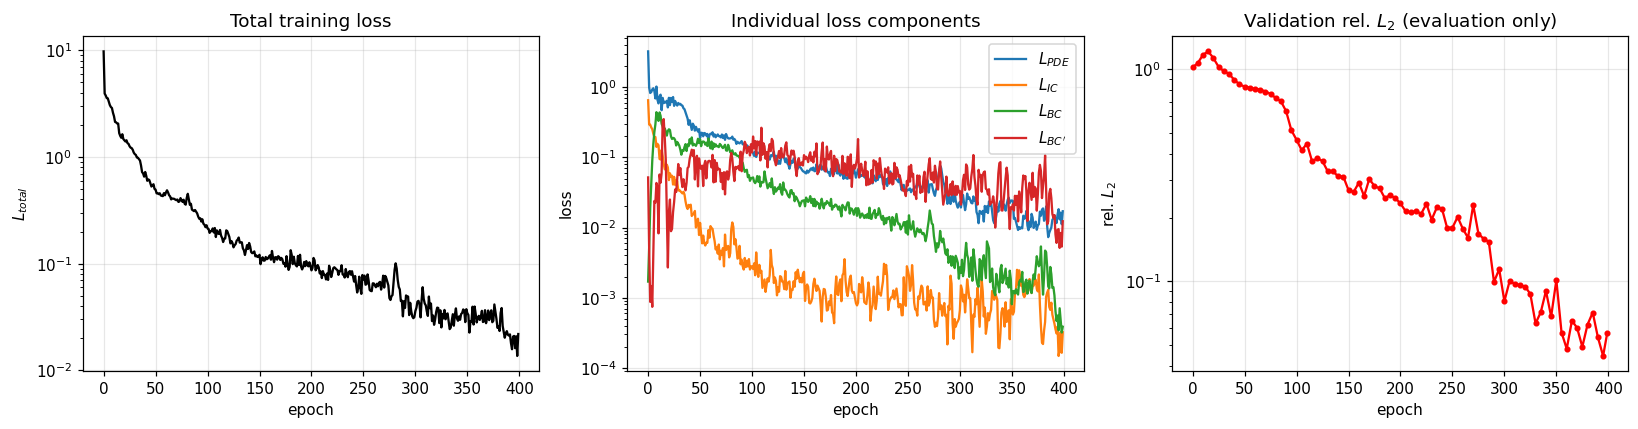

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].semilogy(hist["total"], "k"); ax[0].set_title("Total training loss"); ax[0].set_xlabel("epoch"); ax[0].set_ylabel("$L_{total}$")
for k, lab in [("pde", "$L_{PDE}$"), ("ic", "$L_{IC}$"), ("bc", "$L_{BC}$"), ("bcd", "$L_{BC'}$")]: ax[1].semilogy(hist[k], label=lab)
ax[1].set_title("Individual loss components"); ax[1].set_xlabel("epoch"); ax[1].set_ylabel("loss"); ax[1].legend()
ax[2].semilogy(hist["val_ep"], hist["val"], "r-o", ms=3); ax[2].set_title("Validation rel. $L_2$ (evaluation only)"); ax[2].set_xlabel("epoch"); ax[2].set_ylabel("rel. $L_2$")
plt.tight_layout(); plt.show()

## 7. Reinforcement Learning

### 7.1 What is Reinforcement Learning?

Reinforcement Learning (RL) is a learning approach in which an agent interacts with an environment, takes actions, and receives rewards based on the results.

The agent gradually learns which actions produce better long-term outcomes.

### Main RL Components in This Project

| Term | Meaning in our project |
|---|---|
| Agent | Q-learning algorithm |
| Environment | Transformer training process and collocation pool |
| State | Summary of the PDE residual distribution |
| Action | Selecting a spatial region for new collocation points |
| Reward | Improvement in physics-based validation metrics |
| Policy | Rule used to select an action |
| Episode | One run consisting of multiple sampling actions |
| Exploration | Trying less-visited actions |
| Exploitation | Choosing the action with the highest Q-value |

The objective is to learn which spatial regions should receive additional collocation points to improve the model's physics-based performance.

### 7.2 Q-Learning Update

Q-learning is a model-free reinforcement learning algorithm that learns the expected future reward of taking an action in a particular state.

The Q-table stores these estimated values for every state-action pair.

### Bellman Update Rule

$$
Q(s,a)\leftarrow Q(s,a)+\alpha
\left[r+\gamma\max_{a'}Q(s',a')-Q(s,a)\right]
$$

Where:

- $s$: Current state.
- $a$: Selected action.
- $r$: Reward received.
- $s'$: Next state.
- $\alpha$: Learning rate, set to $0.3$.
- $\gamma$: Discount factor, set to $0.9$.

The update moves the current Q-value towards the reward plus the best estimated future reward. At the final step of an episode, there is no future reward to consider.

### Exploration and Exploitation

The agent uses an $\epsilon$-greedy strategy:

- With probability $\epsilon$, it explores an action.
- Otherwise, it selects the action with the highest Q-value.

Here, $\epsilon$ decreases from $1.0$ to a minimum of $0.1$. During exploration, the agent prefers the least-visited action in the current state, with random tie-breaking.

### 7.3 RL Formulation for Adaptive Sampling

The RL agent decides where new collocation points should be added during Transformer training.

**1. State**

The spatial domain is divided into $K=8$ equal regions. Using 4096 fixed candidate points, the mean squared PDE residual is calculated in each region.

The state consists of:
- The region with the highest mean squared residual.
- A residual concentration category: below $1.5$, below $2.5$, or at least $2.5$.

This produces $8\times3=24$ possible states.

**2. Action**

The agent selects one of the eight regions and adds $M=256$ random collocation points within that region.

**3. Transition**

After adding points, the Transformer is fine-tuned for 40 Adam steps. The residual distribution is then recalculated to obtain the next state.

**4. Reward**

The reward measures the relative reduction in three physics-based validation quantities:

- $R$: Mean squared PDE residual.
- $I$: Initial-condition violation.
- $B$: Periodic boundary and derivative violation.

The reward is:

$$
r=0.5g(R_b,R_a)+0.25g(I_b,I_a)
+0.25g(B_b,B_a)-0.01
$$

where

$$
g(o,n)=\operatorname{clip}
\left(\frac{o-n}{|o|+\epsilon},-1,1\right)
$$

Here, $b$ and $a$ represent measurements before and after an action, respectively, and $\epsilon=10^{-8}$ prevents numerical instability.

**Important:** The reward uses only physics-based improvements. The analytical solution is not used by the RL agent; it is reserved for evaluation.

### 7.4 The RL Environment

The environment connects the Q-learning agent with the Transformer training process.

Its main operations are:

- **Reset:** Restores the baseline model weights and original collocation pool.
- **Observe:** Calculates the residual distribution and determines the current state.
- **Apply:** Adds new points and fine-tunes the Transformer.
- **Step:** Executes the selected region action and returns the next state, reward, and episode status.

The same fine-tuning procedure is used later by Uniform, RAR, and Q-learning, ensuring consistent adaptation steps.

The environment also tracks the number of added points and fine-tuning steps to verify the experimental budget.

In [ ]:
K, M_ADD, T_STEPS, FT, N_STATES = CFG["K"], CFG["M"], CFG["T"], CFG["FT"], CFG["K"] * 3
STEP_COST = 0.01
REW_W = dict(pde=0.5, ic=0.25, bc=0.25); REW_CLIP = 1.0              # physics reward weights / clip
cg = torch.Generator().manual_seed(SEED + 200)
cand_x, cand_t = torch.rand(4096, generator=cg).to(device), torch.rand(4096, generator=cg).to(device)   # fixed candidates for the state
cand_reg = (cand_x * K).long().clamp(max=K - 1)

def rel_gain(old, new, eps=EPS, clip=REW_CLIP):
    """Relative reduction (old-new)/(|old|+eps): epsilon-protected denominator, clipped to [-clip, 1] (safe for ~0 residuals)."""
    assert np.isfinite(old) and np.isfinite(new), "non-finite physics metric"
    return float(np.clip((old - new) / (abs(old) + eps), -clip, 1.0))

def physics_reward(p0, p1):
    """PHYSICS-ONLY reward: PDE-residual, IC-violation and periodic-BC-violation reduction (minus step cost). No analytical error."""
    r = sum(REW_W[k] * rel_gain(p0[k], p1[k]) for k in REW_W) - STEP_COST
    assert np.isfinite(r); return r

def region_points(a, n=M_ADD):
    """Action a -> n random points with x inside region a (x in [a/K,(a+1)/K]) and t ~ U[0,1]."""
    assert 0 <= a < K, f"invalid action {a}"
    return (a + torch.rand(n, device=device)) / K, torch.rand(n, device=device)

class PDEEnv:
    def reset(self):
        self.model = PDETransformer(CFG).to(device); self.model.load_state_dict(BASE_STATE)
        self.opt = torch.optim.Adam(self.model.parameters(), lr=CFG["FT_LR"])
        self.px, self.pt = pool_x0.clone(), pool_t0.clone()
        self.k = 0; self.ft_steps = 0; self.pts_added = 0
        self.phys = phys_metrics(self.model)                 # physics measurements -> reward
        self.err = rel_l2_val(self.model)                    # analytical error: EVALUATION ONLY (history/plots), never used in the reward
        self.state = self.observe(); self.hist = [self.err]; return self.state
    def observe(self):
        r2 = residual_at(self.model, cand_x, cand_t) ** 2
        s = torch.zeros(K, device=device).index_add_(0, cand_reg, r2)
        mr = s / torch.bincount(cand_reg, minlength=K).clamp(min=1)                 # mean r^2 per region
        self.region_res = mr.cpu().numpy()
        conc = (mr.max() / (mr.mean() + EPS)).item()
        st = int(mr.argmax()) * 3 + (0 if conc < 1.5 else 1 if conc < 2.5 else 2)
        assert 0 <= st < N_STATES, f"invalid state {st}"; return st
    def apply(self, xn, tn):
        assert xn.shape == tn.shape == (M_ADD,) and torch.isfinite(xn).all() and torch.isfinite(tn).all()
        assert xn.min() >= 0 and xn.max() <= 1 and tn.min() >= 0 and tn.max() <= 1, "points outside [0,1]^2"
        p0 = self.phys
        self.px, self.pt = torch.cat([self.px, xn]), torch.cat([self.pt, tn])      # add collocation points
        for _ in range(FT): train_step(self.model, self.opt, self.px, self.pt)       # fine-tune (full batch)
        self.ft_steps += FT; self.pts_added += len(xn)
        self.phys = phys_metrics(self.model); self.err = rel_l2_val(self.model)     # err: evaluation only
        reward = physics_reward(p0, self.phys)
        self.k += 1; self.state = self.observe(); self.hist.append(self.err)
        return self.state, reward, self.k >= T_STEPS
    def step(self, a): return self.apply(*region_points(a))

env = PDEEnv(); s0 = env.reset()
print("initial state:", s0, "| region residuals:", env.region_res.round(5), "| pool size:", len(env.px))
assert 0 <= s0 < N_STATES and abs(val_metrics(env.model)[0] - val_metrics(baseline)[0]) < 1e-6   # reset == baseline
# ---- reward unit tests: finite for near-zero / zero / huge-increase cases; sign is right ----
z = dict(pde=0.0, ic=0.0, bc=0.0)
assert np.isfinite(physics_reward(z, z)) and abs(physics_reward(z, z) + STEP_COST) < 1e-12                 # 0/0 -> 0 gain
assert rel_gain(1e-30, 1.0) == -REW_CLIP and abs(rel_gain(1.0, 0.0) - 1.0) < 1e-6 and rel_gain(1.0, 2.0) < 0
assert physics_reward(dict(pde=1., ic=1., bc=1.), dict(pde=.5, ic=.5, bc=.5)) > physics_reward(dict(pde=1., ic=1., bc=1.), dict(pde=2., ic=2., bc=2.))
print("✔ environment ready | physics metrics at reset:", {k: f"{v:.2e}" for k, v in env.phys.items()}, "| ε-protected reward tests passed")

initial state: 23 | region residuals: [0.01063 0.01307 0.00445 0.0082  0.00446 0.0047  0.00555 0.03722] | pool size: 1024
✔ environment ready | physics metrics at reset: {'pde': '8.82e-03', 'ic': '7.96e-05', 'bc': '8.34e-03'} | ε-protected reward tests passed


### 7.5 Q-Learning Agent

A tabular Q-learning agent is implemented using NumPy.

The agent maintains two tables:

- **Q-table:** Stores the estimated value of each state-action pair.
- **Visit-count table:** Tracks how frequently each state-action pair has been selected.

The agent uses $\epsilon$-greedy action selection with count-guided exploration. After receiving a reward, it updates the corresponding Q-value using the Bellman update rule.

For this project, the Q-table contains:

$$
24\text{ states}\times8\text{ actions}=192
$$

possible state-action pairs.

The code also verifies the Q-learning update rule and the least-visited action selection.

In [ ]:
class QAgent:
    def __init__(self, nS, nA, alpha=0.3, gamma=0.9, seed=0, explore="least_visited"):
        self.Q = np.zeros((nS, nA)); self.N = np.zeros((nS, nA), dtype=int)           # Q-table and visit counts
        self.alpha, self.gamma, self.nS, self.nA, self.explore = alpha, gamma, nS, nA, explore
        self.rng = np.random.default_rng(seed)
    def greedy(self, s):
        assert 0 <= s < self.nS; q = self.Q[s]; return int(self.rng.choice(np.flatnonzero(q == q.max())))   # random tie-break
    def act(self, s, eps):
        assert 0 <= s < self.nS and 0 <= eps <= 1
        if self.rng.random() < eps:                                                     # explore
            if self.explore == "least_visited":                                         # count-guided: least-visited action in this state
                n = self.N[s]; return int(self.rng.choice(np.flatnonzero(n == n.min())))
            return int(self.rng.integers(self.nA))
        return self.greedy(s)                                                           # exploit
    def update(self, s, a, r, s2, done):
        assert 0 <= s < self.nS and 0 <= s2 < self.nS and 0 <= a < self.nA and np.isfinite(r), (s, a, s2, r)
        target = r + (0.0 if done else self.gamma * self.Q[s2].max())                  # Bellman target
        td = target - self.Q[s, a]; self.Q[s, a] += self.alpha * td; self.N[s, a] += 1   # move toward target; count the visit
        assert np.isfinite(self.Q).all(), "non-finite Q-value"; return td
    def coverage(self): return int((self.N > 0).sum()), int((self.N.sum(1) > 0).sum())   # visited (s,a) pairs, visited states

# unit tests: update rule on a hand-computed example, and count-guided exploration
tq_ = QAgent(2, 2, alpha=0.5, gamma=0.9); tq_.Q[1] = [0, 4]; tq_.update(0, 0, 1.0, 1, False)
assert abs(tq_.Q[0, 0] - 0.5 * (1 + 0.9 * 4)) < 1e-9 and tq_.N[0, 0] == 1; print("✔ Q-update verified: Q(0,0) =", tq_.Q[0, 0])
tq_.N[1] = [5, 0]; assert tq_.act(1, 1.0) == 1; print("✔ count-guided exploration picks the unvisited action")

✔ Q-update verified: Q(0,0) = 2.3
✔ count-guided exploration picks the unvisited action


### 7.6 Training the RL Agent

The Q-learning agent is trained through multiple episodes.

Each episode follows this process:

1. Reset the environment to the baseline model.
2. Observe the current state.
3. Select an action using the $\epsilon$-greedy policy.
4. Add new collocation points to the selected region.
5. Fine-tune the Transformer.
6. Calculate the physics-based reward.
7. Update the Q-table and move to the next state.

In the full experiment, the agent runs for 60 episodes, with 5 actions per episode.

The notebook records cumulative rewards, final model errors, and the number of visited state-action pairs to assess the learning process.

In [ ]:
agent = QAgent(N_STATES, K, alpha=0.3, gamma=0.9, seed=SEED)
E_N = CFG["EPISODES"]; EPS0, EPS_MIN = 1.0, 0.10
DECAY = (EPS_MIN / EPS0) ** (1 / max(int(0.7 * E_N) - 1, 1))          # epsilon reaches its floor after ~70% of the episodes
ep_rewards, ep_final_err, ep_final_phys, ep_actions = [], [], [], []; rl_ft_steps = rl_pts = 0
set_seed(SEED); t0 = time.time()
for ep in tqdm(range(E_N), desc="RL episodes"):
    eps = max(EPS_MIN, EPS0 * DECAY ** ep); s = env.reset(); R = 0; acts = []
    for k in range(T_STEPS):
        assert 0 <= s < N_STATES
        a = agent.act(s, eps); assert 0 <= a < K
        s2, r, done = env.step(a)
        assert np.isfinite(r) and 0 <= s2 < N_STATES
        agent.update(s, a, r, s2, done)
        s, R = s2, R + r; acts.append(a)
    ep_rewards.append(R); ep_final_err.append(env.err); ep_final_phys.append(phys_score(env.phys)); ep_actions.append(acts)   # err: evaluation only
    rl_ft_steps += env.ft_steps; rl_pts += env.pts_added
RL_TRAIN_TIME = time.time() - t0
assert np.isfinite(agent.Q).all() and np.isfinite(ep_rewards).all()
assert rl_ft_steps == E_N * T_STEPS * FT and rl_pts == E_N * T_STEPS * M_ADD and agent.N.sum() == E_N * T_STEPS
vis_pairs, vis_states = agent.coverage(); n_trans, n_pairs = E_N * T_STEPS, N_STATES * K
print(f"RL policy learning: {RL_TRAIN_TIME:.0f}s, {rl_ft_steps} fine-tune steps | physics rewards first/last episode: {ep_rewards[0]:.3f} / {ep_rewards[-1]:.3f}")
print(f"visited (s,a) pairs: {vis_pairs} of {n_pairs} ({vis_pairs/n_pairs:.0%}) | visited states: {vis_states} of {N_STATES} | transitions collected: {n_trans} (≈{n_trans/n_pairs:.2f} per table entry)")
print("Q-values finite ✔ | max visits of one (s,a):", int(agent.N.max()))
if n_trans < 10 * n_pairs: print("⚠ fewer than ~10 visits per (s,a) on average -> Q-values are NOT expected to have converged (see 7.7)")

RL episodes:   0%|          | 0/60 [00:00<?, ?it/s]

RL policy learning: 1417s, 12000 fine-tune steps | physics rewards first/last episode: -0.579 / -0.884
visited (s,a) pairs: 40 of 192 (21%) | visited states: 11 of 24 | transitions collected: 300 (≈1.56 per table entry)
Q-values finite ✔ | max visits of one (s,a): 50
⚠ fewer than ~10 visits per (s,a) on average -> Q-values are NOT expected to have converged (see 7.7)


### 7.7 Exploration, Coverage and Convergence

Q-learning needs sufficient exploration to estimate the values of different state-action pairs.

However, convergence is not guaranteed in this experiment because:

- Only a limited number of training episodes are available.
- Many state-action pairs may remain unvisited.
- Rewards can vary due to random point generation and stochastic fine-tuning.
- The state is a simplified summary of a more complex training process.
- The learning rate remains constant.

Therefore, the learned Q-table should be treated as an estimate rather than a fully converged optimal policy.

The notebook reports visited state-action pairs and visited states to measure how much of the Q-table has actually been explored.

## 8. Comparative Experiment

Three sampling strategies are compared using the same baseline Transformer.

**A. Uniform Sampling**

Adds random collocation points across the entire spatial-temporal domain.

**B. Residual-Based Adaptive Refinement (RAR)**

Generates 10,000 candidate points and selects the 256 points with the highest absolute PDE residual.

**C. Q-Learning**

Uses the learned policy to select a spatial region and adds 256 random points within that region.

### Fair Comparison

All three methods use:

- The same baseline model and initial collocation pool.
- The same number of added points.
- The same number of fine-tuning steps.
- The same optimizer and learning rate.
- The same independent test grid.

Each method is repeated using three random seeds, and results are reported as mean and standard deviation.

The additional cost of training the Q-learning policy is reported separately because it is not included in the adaptation budget.

In [ ]:
N_RAR_CAND = 10000
def choose_uniform(env): return torch.rand(M_ADD, device=device), torch.rand(M_ADD, device=device)
def choose_rar(env):
    cx, ct = torch.rand(N_RAR_CAND, device=device), torch.rand(N_RAR_CAND, device=device)
    idx = residual_at(env.model, cx, ct).abs().topk(M_ADD).indices; return cx[idx], ct[idx]
def choose_rl(env):
    a = agent.greedy(env.state); assert 0 <= a < K; env.last_a = a; return region_points(a)       # greedy policy (eps = 0)

results = {n: [] for n in ["Uniform", "RAR", "Q-Learning"]}; hists = {n: [] for n in results}; keep = {}
for name, chooser in [("Uniform", choose_uniform), ("RAR", choose_rar), ("Q-Learning", choose_rl)]:
    for rep in range(CFG["N_REPEAT"]):
        set_seed(SEED + 1000 + rep); s = env.reset(); t0 = time.time(); acts = []
        for k in range(T_STEPS):
            xn, tn = chooser(env); env.apply(xn, tn)
            if name == "Q-Learning": acts.append(env.last_a)
        adapt_time = time.time() - t0
        # ---- budget audit: identical points and fine-tune steps for every method ----
        assert len(env.px) == N0 + T_STEPS * M_ADD and env.pts_added == T_STEPS * M_ADD and env.ft_steps == T_STEPS * FT, "budget mismatch"
        m = evaluate(env.model); pm = phys_metrics(env.model)                                  # test metrics (analytical, evaluation only) + physics
        m.update(time=adapt_time, npts=len(env.px), ft_steps=env.ft_steps, ValPhys=phys_score(pm)); results[name].append(m); hists[name].append(list(env.hist))
        if rep == 0: keep[name] = dict(model=copy.deepcopy(env.model), px=env.px.clone(), pt=env.pt.clone(), acts=acts)
    r = results[name]; print(f"{name:11s} RelL2 = {np.mean([x['RelL2'] for x in r]):.4f} ± {np.std([x['RelL2'] for x in r]):.4f} | pts = {r[0]['npts']} | fine-tune steps = {r[0]['ft_steps']}")

# ---- budget ledger (adaptation phase) and SEPARATE policy-learning cost ----
ledger = pd.DataFrame([dict(Method=n, Start_pts=N0, Added_pts=T_STEPS * M_ADD, FT_steps=results[n][0]["ft_steps"], Optimizer="Adam", FT_LR=CFG["FT_LR"],
                            State_obs_per_step=len(cand_x), Selection_resid_evals_per_step=N_RAR_CAND if n == "RAR" else 0) for n in results])
print("\nBUDGET LEDGER (adaptation phase, identical sampling + fine-tuning budget):"); print(ledger.to_string(index=False))
assert ledger[["Added_pts", "FT_steps", "FT_LR"]].nunique().max() == 1
print(f"\nADDITIONAL POLICY-LEARNING COST of Q-Learning (paid once, NOT included above): {E_N} episodes, {rl_ft_steps} fine-tune steps, "
      f"{rl_pts} points generated, {RL_TRAIN_TIME:.0f}s wall-time (≈ {rl_ft_steps / (T_STEPS * FT):.1f}x the fine-tuning of one adaptation run)")

Uniform     RelL2 = 0.0201 ± 0.0037 | pts = 2304 | fine-tune steps = 200
RAR         RelL2 = 0.0348 ± 0.0036 | pts = 2304 | fine-tune steps = 200
Q-Learning  RelL2 = 0.0331 ± 0.0029 | pts = 2304 | fine-tune steps = 200

BUDGET LEDGER (adaptation phase, identical sampling + fine-tuning budget):
    Method  Start_pts  Added_pts  FT_steps Optimizer  FT_LR  State_obs_per_step  Selection_resid_evals_per_step
   Uniform       1024       1280       200      Adam 0.0005                4096                               0
       RAR       1024       1280       200      Adam 0.0005                4096                           10000
Q-Learning       1024       1280       200      Adam 0.0005                4096                               0

ADDITIONAL POLICY-LEARNING COST of Q-Learning (paid once, NOT included above): 60 episodes, 12000 fine-tune steps, 76800 points generated, 1417s wall-time (≈ 60.0x the fine-tuning of one adaptation run)


## 9. Visualisation of Results

This section visualises the learned solution and compares the sampling strategies.

The plots include:

- **Solution curves:** Compare Transformer predictions with the analytical solution at different time points.
- **Heatmaps:** Show the analytical solution, predicted solution, absolute prediction error, and PDE residual.
- **Collocation-point distributions:** Show where each sampling method adds new training points.
- **RL reward curve:** Shows how cumulative physics-based rewards change across episodes.
- **Q-table:** Visualises the learned state-action values.
- **Method comparison:** Tracks validation error during adaptation and compares final test errors.

The model used for the solution visualisations is automatically selected based on the lowest mean test relative $L_2$ error among the three adaptation methods.

Model used for solution plots: Uniform


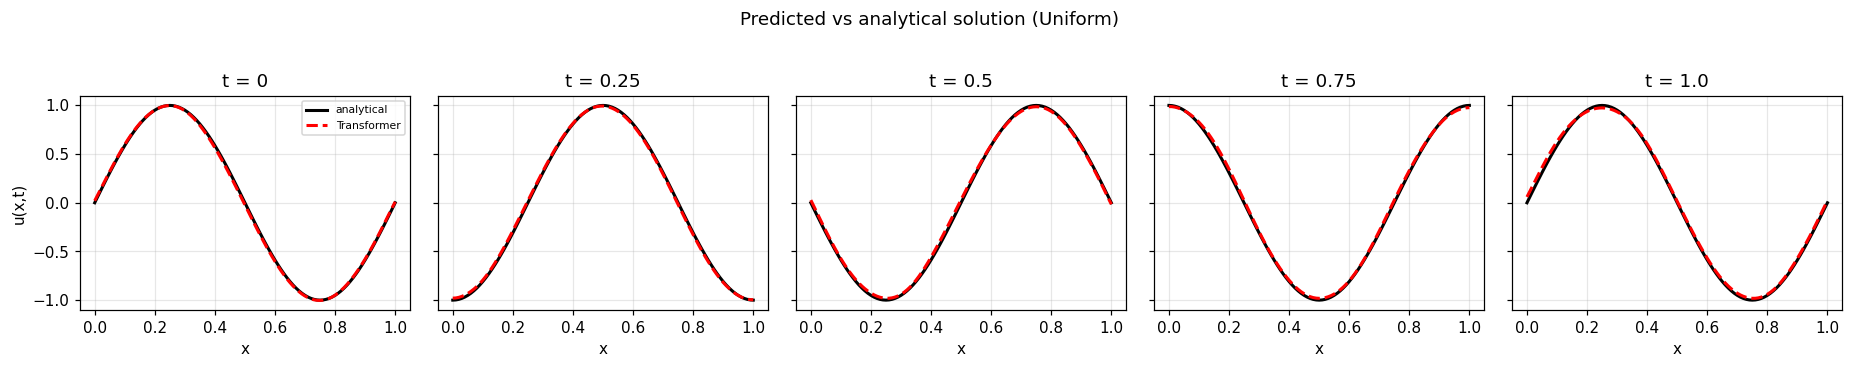

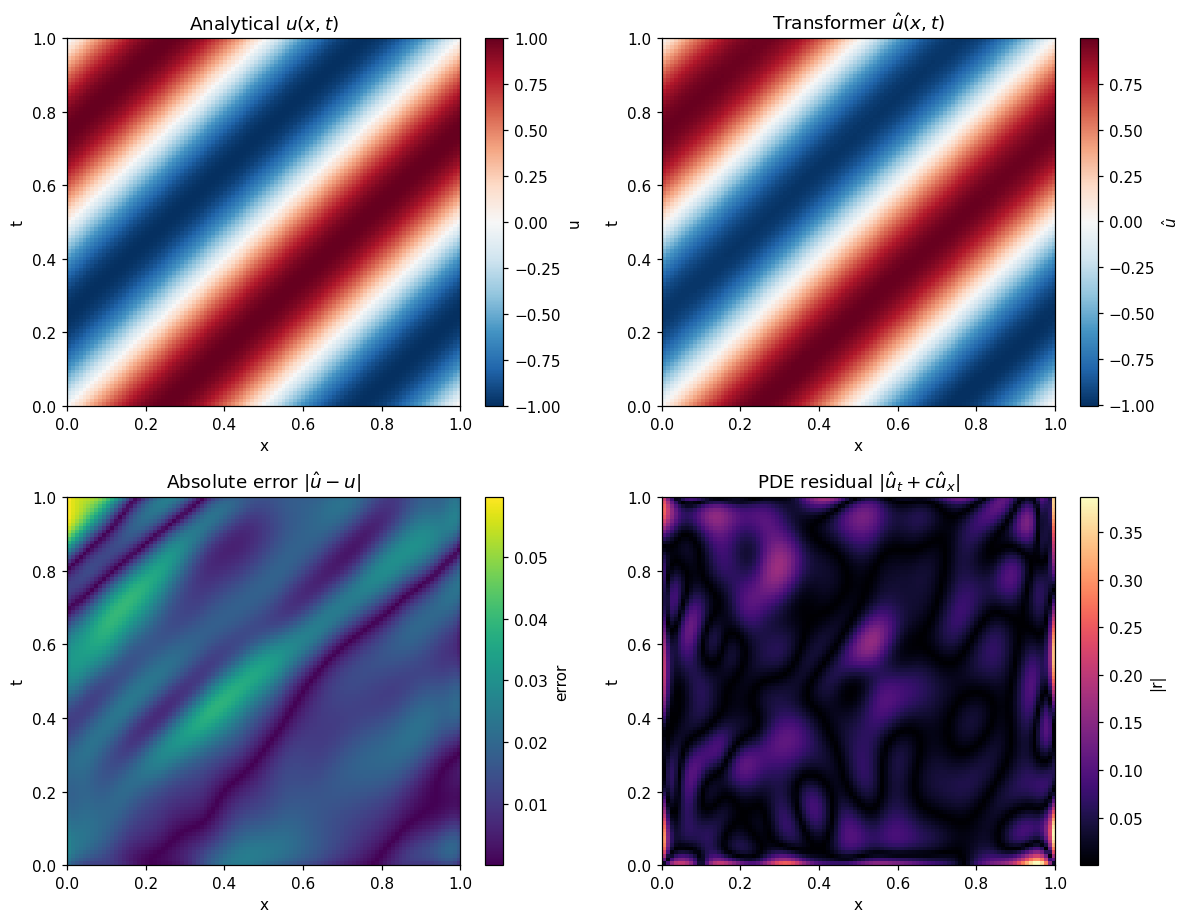

In [ ]:
best_name = min(results, key=lambda n: np.mean([x["RelL2"] for x in results[n]]))
bm = keep[best_name]["model"]; print("Model used for solution plots:", best_name)
U = predict(bm, test_x, test_t).cpu().numpy().reshape(NT, NT); UE = test_u.cpu().numpy().reshape(NT, NT)
ERR = np.abs(U - UE); RES = residual_at(bm, test_x, test_t).cpu().numpy().reshape(NT, NT)
ext = [0, 1, 0, 1]

# plots 3-4: predicted vs analytical at several times
fig, ax = plt.subplots(1, 5, figsize=(17, 3.2), sharey=True)
for a_, tv in zip(ax, [0, .25, .5, .75, 1.0]):
    j = int(round(tv * (NT - 1))); a_.plot(xg := np.linspace(0, 1, NT), UE[:, j], "k", lw=2, label="analytical"); a_.plot(xg, U[:, j], "r--", lw=2, label="Transformer")
    a_.set_title(f"t = {tv}"); a_.set_xlabel("x")
ax[0].set_ylabel("u(x,t)"); ax[0].legend(fontsize=7); plt.suptitle(f"Predicted vs analytical solution ({best_name})", y=1.03); plt.tight_layout(); plt.show()

# plots 5-8: heatmaps
fig, ax = plt.subplots(2, 2, figsize=(11, 8.5))
for a_, Z, ttl, cm, lab in [(ax[0,0], UE, "Analytical $u(x,t)$", "RdBu_r", "u"), (ax[0,1], U, "Transformer $\\hat u(x,t)$", "RdBu_r", "$\\hat u$"),
                            (ax[1,0], ERR, "Absolute error $|\\hat u-u|$", "viridis", "error"), (ax[1,1], np.abs(RES), "PDE residual $|\\hat u_t+c\\hat u_x|$", "magma", "|r|")]:
    im = a_.imshow(Z.T, origin="lower", extent=ext, aspect="auto", cmap=cm); a_.set_title(ttl); a_.set_xlabel("x"); a_.set_ylabel("t"); a_.grid(False); plt.colorbar(im, ax=a_, label=lab)
plt.tight_layout(); plt.show()

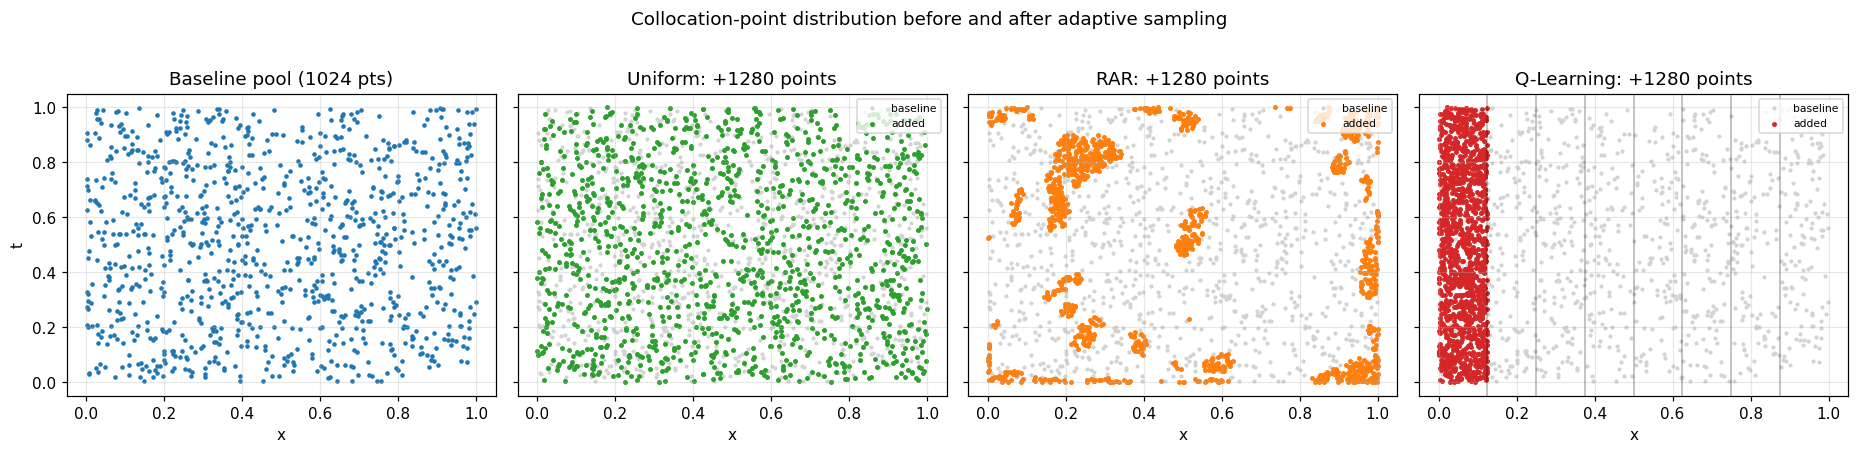

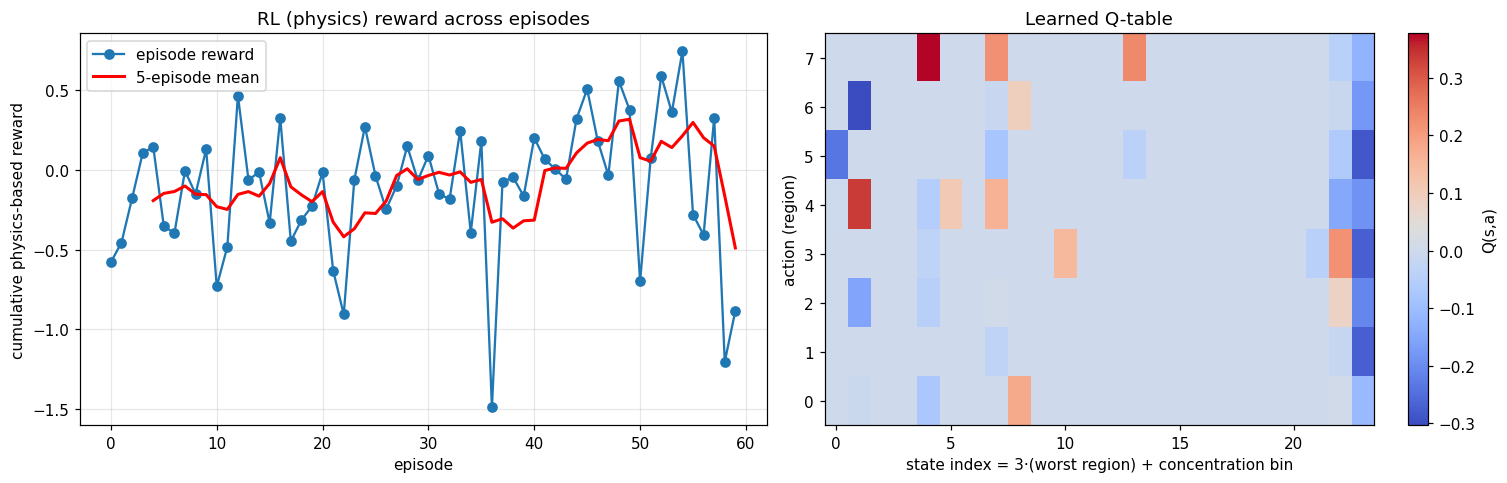

In [ ]:
# plot 11: collocation points before / after
fig, ax = plt.subplots(1, 4, figsize=(17, 4), sharey=True)
ax[0].scatter(pool_x0.cpu(), pool_t0.cpu(), s=4, c="C0"); ax[0].set_title(f"Baseline pool ({N0} pts)")
for a_, n, c in zip(ax[1:], ["Uniform", "RAR", "Q-Learning"], ["C2", "C1", "C3"]):
    p = keep[n]; a_.scatter(pool_x0.cpu(), pool_t0.cpu(), s=3, c="lightgray", label="baseline"); a_.scatter(p["px"][N0:].cpu(), p["pt"][N0:].cpu(), s=5, c=c, label="added")
    a_.set_title(f"{n}: +{len(p['px'])-N0} points"); a_.legend(fontsize=7, loc="upper right")
for a_ in ax: a_.set_xlabel("x")
for r_ in range(1, K): ax[3].axvline(r_ / K, c="k", lw=.3)
ax[0].set_ylabel("t"); plt.suptitle("Collocation-point distribution before and after adaptive sampling", y=1.02); plt.tight_layout(); plt.show()

# plots 12-13: RL rewards and Q-table
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].plot(ep_rewards, "o-", label="episode reward"); w_ = min(5, len(ep_rewards))
if len(ep_rewards) >= w_: ax[0].plot(np.arange(w_ - 1, len(ep_rewards)), np.convolve(ep_rewards, np.ones(w_) / w_, "valid"), "r", lw=2, label=f"{w_}-episode mean")
ax[0].set_xlabel("episode"); ax[0].set_ylabel("cumulative physics-based reward"); ax[0].set_title("RL (physics) reward across episodes"); ax[0].legend()
im = ax[1].imshow(agent.Q.T, aspect="auto", cmap="coolwarm", origin="lower"); plt.colorbar(im, ax=ax[1], label="Q(s,a)")
ax[1].set_xlabel("state index = 3·(worst region) + concentration bin"); ax[1].set_ylabel("action (region)"); ax[1].set_title("Learned Q-table"); ax[1].grid(False)
plt.tight_layout(); plt.show()

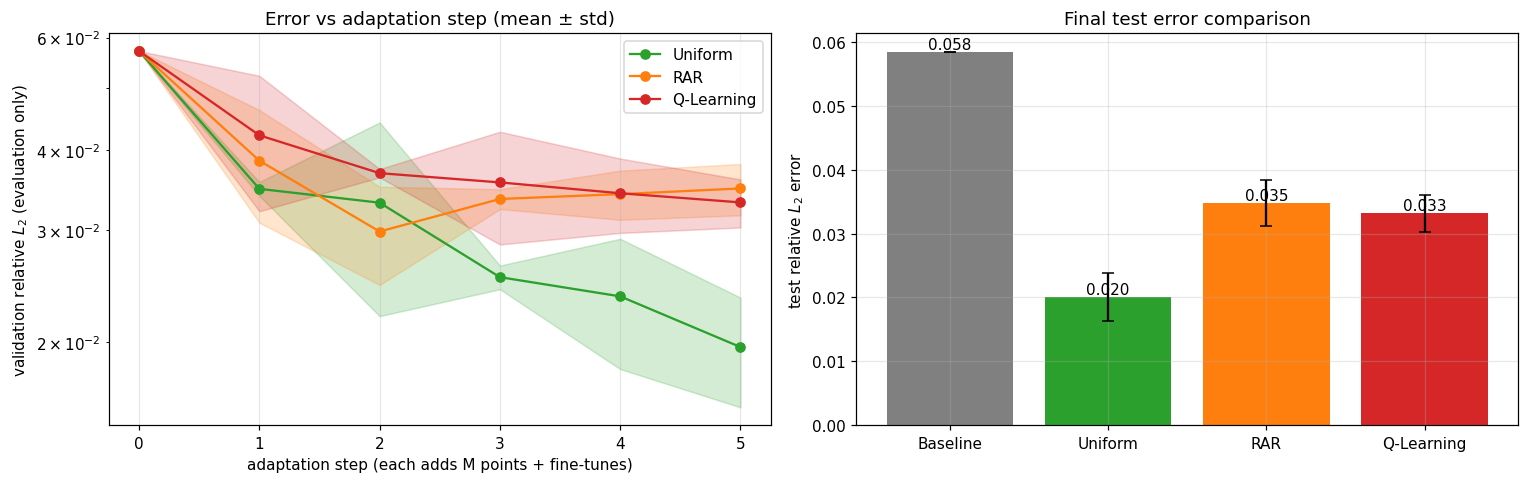

In [ ]:
# plots 14-15: method comparison
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for n, c in zip(results, ["C2", "C1", "C3"]):
    H = np.array(hists[n]); mu, sd = H.mean(0), H.std(0); st = np.arange(len(mu))
    ax[0].plot(st, mu, "o-", c=c, label=n); ax[0].fill_between(st, mu - sd, mu + sd, color=c, alpha=.2)
ax[0].set_yscale("log"); ax[0].set_xlabel("adaptation step (each adds M points + fine-tunes)"); ax[0].set_ylabel("validation relative $L_2$ (evaluation only)")
ax[0].set_title("Error vs adaptation step (mean ± std)"); ax[0].legend()
names = ["Baseline"] + list(results); vals = [base_metrics["RelL2"]] + [np.mean([x["RelL2"] for x in results[n]]) for n in results]
errs = [0] + [np.std([x["RelL2"] for x in results[n]]) for n in results]
bars = ax[1].bar(names, vals, yerr=errs, color=["gray", "C2", "C1", "C3"], capsize=4); ax[1].set_ylabel("test relative $L_2$ error"); ax[1].set_title("Final test error comparison")
for b_, v_ in zip(bars, vals): ax[1].text(b_.get_x() + b_.get_width() / 2, v_, f"{v_:.3f}", ha="center", va="bottom")
plt.tight_layout(); plt.show()

## 10. Results and Automated Analysis

The final results are evaluated using an independent $101\times101$ test grid.

The notebook reports:

- **MSE:** Mean squared prediction error.
- **MAE:** Mean absolute prediction error.
- **Relative $L_2$ error:** Overall prediction error relative to the analytical solution.
- **Residual MSE:** Mean squared PDE residual.
- **Fine-tuning steps:** Number of adaptation updates.
- **Validation physics loss:** Combined PDE, initial-condition, and boundary-condition violations.
- **Time:** Wall-clock time for the measured training or adaptation phase.

Results for the adaptive methods are reported as mean $\pm$ standard deviation over three runs.

The additional policy-learning time for Q-learning is reported separately, so its computational cost is not hidden.

The automated analysis identifies the best method according to relative $L_2$ error, PDE residual, and physics validation loss.

In [ ]:
rows = [dict(Method="Baseline (no adaptation)", Points=N0, MSE=base_metrics["MSE"], MAE=base_metrics["MAE"], RelL2=f'{base_metrics["RelL2"]:.4f}',
             ResMSE=base_metrics["ResMSE"], FT_steps=0, ValPhys=phys_score(base_phys), Time_s=round(BASE_TIME, 1))]
for n, r in results.items():
    mean = lambda k: np.mean([x[k] for x in r])
    rows.append(dict(Method=n, Points=r[0]["npts"], MSE=mean("MSE"), MAE=mean("MAE"),
                     RelL2=f'{mean("RelL2"):.4f} ± {np.std([x["RelL2"] for x in r]):.4f}', ResMSE=mean("ResMSE"), FT_steps=r[0]["ft_steps"], ValPhys=mean("ValPhys"), Time_s=round(mean("time"), 1)))
df = pd.DataFrame(rows); pd.options.display.float_format = "{:.3e}".format
print(df.to_string(index=False))

mu = {n: np.mean([x["RelL2"] for x in r]) for n, r in results.items()}; rs = {n: np.mean([x["ResMSE"] for x in r]) for n, r in results.items()}
tm = {n: np.mean([x["time"] for x in r]) for n, r in results.items()}
print("\n=== AUTOMATED SUMMARY ===")
print(f"Best method by relative L2 : {min(mu, key=mu.get)} ({min(mu.values()):.4f})   | baseline before adaptation: {base_metrics['RelL2']:.4f}")
print(f"Lowest PDE residual        : {min(rs, key=rs.get)} ({min(rs.values()):.3e})")
print(f"Cheapest adaptation phase  : {min(tm, key=tm.get)} ({min(tm.values()):.1f}s) | (adaptation phase only)")
print(f"Policy-learning cost (separate): {RL_TRAIN_TIME:.0f}s and {rl_ft_steps} fine-tune steps, paid once before the Q-Learning row can be used")
pv = {n: np.mean([x["ValPhys"] for x in r]) for n, r in results.items()}; print(f"Lowest physics validation loss: {min(pv, key=pv.get)} ({min(pv.values()):.3e})")
print(f"RUN_MODE = {RUN_MODE}" + ("  -> smoke-test budgets: differences are NOT scientific evidence" if RUN_MODE == "QUICK_RUN" else ""))
r_ = np.array(ep_rewards); th = max(1, len(r_) // 3)
slope = np.polyfit(np.arange(len(r_)), r_, 1)[0] if len(r_) > 1 else 0.0
print(f"Visited (s,a) pairs: {vis_pairs}/{n_pairs}, visited states {vis_states}/{N_STATES}")
print(f"RL reward: first-third mean {r_[:th].mean():.3f} -> last-third mean {r_[-th:].mean():.3f} (slope {slope:+.4f}/episode)")
gap = (mu["Q-Learning"] - mu["RAR"]) / (abs(mu["RAR"]) + EPS) * 100          # epsilon-protected
print(f"Q-Learning vs RAR (rel-L2): {gap:+.1f}%  ->", "RL better" if gap < -5 else "RL worse" if gap > 5 else "no clear difference (within ~5%, check the ± std)")
print("Caveat: few episodes/repeats, noisy rewards, single PDE; differences smaller than the std are not evidence of superiority.")

                  Method  Points       MSE       MAE           RelL2    ResMSE  FT_steps   ValPhys    Time_s
Baseline (no adaptation)    1024 1.707e-03 3.295e-02          0.0584 1.137e-02         0 1.796e-02 1.915e+02
                 Uniform    2304 2.082e-04 1.176e-02 0.0201 ± 0.0037 3.902e-03       200 1.004e-02 2.330e+01
                     RAR    2304 6.112e-04 1.820e-02 0.0348 ± 0.0036 4.715e-03       200 8.006e-03 2.370e+01
              Q-Learning    2304 5.535e-04 1.870e-02 0.0331 ± 0.0029 7.107e-03       200 7.348e-03 2.370e+01

=== AUTOMATED SUMMARY ===
Best method by relative L2 : Uniform (0.0201)   | baseline before adaptation: 0.0584
Lowest PDE residual        : Uniform (3.902e-03)
Cheapest adaptation phase  : Uniform (23.3s) | (adaptation phase only)
Policy-learning cost (separate): 1417s and 12000 fine-tune steps, paid once before the Q-Learning row can be used
Lowest physics validation loss: Q-Learning (7.348e-03)
RUN_MODE = FULL_RUN
Visited (s,a) pairs: 40/192, visit

### Scientific Interpretation of Results

The baseline provides the starting performance. Improvements over it reflect the benefit of additional collocation points and fine-tuning, so the main comparison is between the three sampling strategies under equal adaptation budgets.

**Key observations:**

- Uniform sampling achieved the lowest mean test relative $L_2$ error and PDE residual.
- RAR selects individual high-residual points, while Q-learning selects an entire spatial region and samples randomly within it.
- Q-learning achieved a slightly lower relative $L_2$ error than RAR, but the difference was small compared with the reported variation.
- Q-learning required substantial additional computation to learn its policy.

The limited number of episodes, incomplete Q-table coverage, noisy rewards, and coarse state representation may have affected RL performance.

Also, the RL reward optimises physics-based violations, whereas final relative $L_2$ error measures agreement with the analytical solution. These metrics do not necessarily produce the same ranking.

Therefore, this experiment demonstrates that Q-learning can interact with and guide adaptive PDE sampling, but it does not establish that RL is superior to Uniform or RAR for this problem.

## 11. Conclusion and Future Work

### Conclusion

This project combines a Transformer-based physics-informed model with reinforcement learning for adaptive collocation-point sampling.

The Transformer predicts the PDE solution using the initial-condition context and query coordinates. Its training loss penalises PDE residuals, initial-condition violations, and periodic boundary violations.

The Q-learning agent observes the residual distribution, selects a spatial region for additional collocation points, and receives a reward based on improvements in physics-based validation metrics.

The experiments show that all three adaptation methods improve upon the baseline. Uniform sampling achieves the best mean test relative $L_2$ error in this experiment, while Q-learning demonstrates a working RL-based sampling strategy without outperforming the other methods.

### Limitations

- Only one smooth linear advection PDE is considered.
- The model uses a fixed initial condition.
- RL uses a small tabular state-action space and a limited number of episodes.
- Rewards are affected by stochastic fine-tuning.
- The decoder uses independent length-one queries, making its self-attention trivial.
- Learning the RL policy introduces additional computational cost.

### Future Work

- Extend the approach to nonlinear PDEs such as Burgers' equation.
- Train on multiple initial conditions.
- Explore DQN or PPO for larger state spaces.
- Allow the agent to select both spatial and temporal regions.
- Perform experiments with more random seeds and episodes.
- Investigate more effective reward functions and computational budgets.

# Final project summary

In [ ]:
print("="*70); print("PROJECT SUMMARY"); print("="*70)
print(f"PDE            : u_t + {C_ADV} u_x = 0, IC sin(2πx), periodic BC; exact u = sin(2π(x-ct))")
print(f"Model          : encoder-decoder Transformer from scratch, d={CFG['d_model']}, heads={CFG['n_heads']}, "
      f"{CFG['n_enc']} enc + {CFG['n_dec']} dec layers, {sum(p.numel() for p in baseline.parameters()):,} params")
print(f"Loss           : PDE + IC + periodic BC + periodic-derivative BC (autograd), weights {LAM}")
print(f"Baseline       : {N0} pts, {CFG['EPOCHS']} epochs, test rel-L2 = {base_metrics['RelL2']:.4f}")
print(f"Run mode       : {RUN_MODE} | decoder mode: {DECODER_MODE} (decoder self-attention is trivial; cross-attention carries the IC information)")
print(f"RL             : tabular Q-learning, {N_STATES} states x {K} actions, {E_N} episodes x {T_STEPS} steps, α=0.3, γ=0.9, PHYSICS-only reward (PDE/IC/BC reduction)")
print(f"RL coverage    : {vis_pairs}/{n_pairs} (s,a) pairs visited | policy-learning cost (separate): {rl_ft_steps} fine-tune steps, {RL_TRAIN_TIME:.0f}s")
for n in results: print(f"{n:11s}    : rel-L2 {mu[n]:.4f} | residual {rs[n]:.2e} | time {tm[n]:.1f}s | points {results[n][0]['npts']}")
print(f"Winner (rel-L2): {min(mu, key=mu.get)}  — interpret with the ± std shown above.")
print("="*70)

PROJECT SUMMARY
PDE            : u_t + 1.0 u_x = 0, IC sin(2πx), periodic BC; exact u = sin(2π(x-ct))
Model          : encoder-decoder Transformer from scratch, d=64, heads=4, 2 enc + 2 dec layers, 168,129 params
Loss           : PDE + IC + periodic BC + periodic-derivative BC (autograd), weights {'pde': 1.0, 'ic': 10.0, 'bc': 1.0, 'd': 0.1}
Baseline       : 1024 pts, 400 epochs, test rel-L2 = 0.0584
Run mode       : FULL_RUN | decoder mode: independent (decoder self-attention is trivial; cross-attention carries the IC information)
RL             : tabular Q-learning, 24 states x 8 actions, 60 episodes x 5 steps, α=0.3, γ=0.9, PHYSICS-only reward (PDE/IC/BC reduction)
RL coverage    : 40/192 (s,a) pairs visited | policy-learning cost (separate): 12000 fine-tune steps, 1417s
Uniform        : rel-L2 0.0201 | residual 3.90e-03 | time 23.3s | points 2304
RAR            : rel-L2 0.0348 | residual 4.71e-03 | time 23.7s | points 2304
Q-Learning     : rel-L2 0.0331 | residual 7.11e-03 | time 2